# Simulación Monte Carlo — Siemens Artis Zee Ceiling

Notebook consolidado para el Trabajo Final de Graduación. El flujo está organizado en: configuración experimental, espectro, geometría, simulación principal, normalización en el IRP, cálculo de $\dot H^*(10)$, validación experimental y generación de mapas/curvas de isodosis.

**Criterio de uso:** los parámetros experimentales y los parámetros adoptados como hipótesis de modelado se mantienen explícitamente separados.


## 1. Importaciones, unidades y configuración general

Esta celda contiene la única definición de los parámetros globales del modelo. Evite redefinir estas constantes en celdas posteriores.


In [1]:

from pathlib import Path

import SimpleITK as sitk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Ellipse
import uproot


import opengate as gate

from scipy.spatial.transform import Rotation


# ============================================================
# UNIDADES
# ============================================================

from opengate.utility import g4_units

mm  = gate.g4_units.mm
cm  = gate.g4_units.cm
m   = gate.g4_units.m
keV = gate.g4_units.keV
deg = gate.g4_units.deg


# ============================================================
# ARCHIVOS
# ============================================================

SPECTRUM_FILE = Path("spectrum_73_kV.txt")

OUTPUT_DIR = Path("output_artis_zee")
MAIN_OUTPUT_DIR = OUTPUT_DIR / "main"
NORM_OUTPUT_DIR = OUTPUT_DIR / "normalization"
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SAVE_FIGURES = True
FIGURE_DPI = 600


# ============================================================
# SISTEMA DE ANGIOGRAFÍA
# ============================================================

SYSTEM_NAME = "Siemens Artis Zee Ceiling"
TUBE_MODEL = "MEGALIX Cat Plus 125/20/40/80-122GW"


# ============================================================
# CONDICIÓN EXPERIMENTAL / HIPÓTESIS DE MODELADO
# ============================================================

# Valores representativos obtenidos de los registros experimentales.
TUBE_VOLTAGE_KV = 73.3
TUBE_CURRENT_MA = 240.6

# Fluoroscopia pulsada.
PULSE_RATE_HZ = 7.5
PULSE_WIDTH_MS = 3.5

# Tiempo medio representativo de las repeticiones.
EXPOSURE_TIME_S = 3

MAS = (
    TUBE_CURRENT_MA
    * (PULSE_WIDTH_MS / 1000.0)
    * PULSE_RATE_HZ
    * EXPOSURE_TIME_S
)

# Espectro SpekPy final utilizado para el muestreo energético.
CU_FILTER_MM = 0.1
AL_EQUIV_MM = 0.2
HVL_AL_MM = 2.79
SPEKPY_MEAN_ENERGY_KEV = 42.5
ANODE_ANGLE_DEG = 12.0

# ============================================================
# GEOMETRÍA DEL C-ARM
# ============================================================

LAO_DEG = -35.0
CRAN_CAUD_DEG = 0.0

SID_CM = 104.0
SOURCE_TO_ISOCENTER_CM = 78.5
ISOCENTER_TO_FLOOR_CM = 108.0

# El certificado de control de calidad reportó un campo real
# de 20.74 cm para el FOV nominal de 22 cm, referido a 100 cm.
FOV_NOMINAL_CM = 22.0
FIELD_MEASURED_CM = 20.74
FIELD_REFERENCE_DISTANCE_CM = 100.0

# ============================================================
# RECEPTOR / BLINDAJE POSTERIOR
# ============================================================

LEAD_BACKING_DISTANCE_ISO_CM = 30.0
LEAD_BACKING_THICKNESS_MM = 1.5

# Dimensiones laterales del blindaje

LEAD_BACKING_WIDTH_CM = 30.0
LEAD_BACKING_HEIGHT_CM = 30.0

DETECTOR_BACKING_THICKNESS_MM = 1.5

# ============================================================
# MESA
# ============================================================

TABLE_WIDTH_CM = 45.0
TABLE_LENGTH_CM = 228.6

# Tablero <= 1.4 mm Al eq + colchoneta < 0.6 mm Al eq
TABLE_EQ_AL_THICKNESS_MM = 2.0

# Posición experimental de la superficie superior del tablero
# respecto al isocentro.
TABLE_TOP_Z_CM = -19.0


# ============================================================
# NÚMERO DE HISTORIAS
# ============================================================




N_PRIMARIES = 1_200_000_000


N_PRIMARIES_NORMALIZATION = 120_000_000


N_THREADS = 1

N_PRIMARIES_PER_THREAD = (
    N_PRIMARIES // N_THREADS
)


N_PRIMARIES_PER_THREAD_NORMALIZATION = (
    N_PRIMARIES_NORMALIZATION // N_THREADS
)


# ============================================================
# CONTROL DEL TRANSPORTE Y NORMALIZACIÓN IRP
# ============================================================

IRP_DETECTOR_WIDTH_CM = 5.0
IRP_DETECTOR_THICKNESS_CM = 0.1
IRP_PLANE_THICKNESS_MM = 0.1
MAX_STEP_AIR_CM = 5.0

# ============================================================
# CRITERIO DE CONVERGENCIA
# ============================================================

TARGET_RELATIVE_UNCERTAINTY_PERCENT = 10.0
ROI_RELATIVE_DOSE_THRESHOLD_PERCENT = 5.0


## 2. Sala, plano de medición y puntos experimentales

Las posiciones se expresan respecto al isocentro. Los valores `measured_msv_h` corresponden a la tasa experimental de equivalente de dosis ambiental $\dot H^*(10)$ registrada con el RaySafe 452.


In [2]:
# ============================================================
# TAMAÑO DE LA SALA
# ============================================================


ROOM_SIZE_X_CM = 618.0
ROOM_SIZE_Y_CM = 800.0


ROOM_SIZE_Z_CM = 300.0

WORLD_MARGIN_CM = 20.0


# ============================================================
# ALTURA DEL DOSÍMETRO
# ============================================================


DOSIMETER_HEIGHT_FLOOR_CM = 124.0

DOSIMETER_Z_CM = (
    DOSIMETER_HEIGHT_FLOOR_CM
    - ISOCENTER_TO_FLOOR_CM
)


# ============================================================
# RESOLUCIÓN DEL MAPA DE SALA
# ============================================================

ROOM_VOXEL_CM = 5.0
ROOM_PLANE_THICKNESS_CM = 5.0

# Volumen virtual de scoring para cada punto experimental.
POINT_SCORING_SIZE_CM = 10.0


# ============================================================
# PUNTOS EXPERIMENTALES
# ============================================================
#

MEASUREMENT_POINTS = {

    # Distancia al maniquí = 54 cm
    "Medico_1": {
        "x_cm": 38.0,
        "y_cm": -38.0,
        "measured_msv_h": 2.738,
        "u_measured_msv_h": 0.0430,
    },

    # Distancia al maniquí = 130 cm
    "Enfermero_1": {
        "x_cm": 117.0,
        "y_cm": -57.0,
        "measured_msv_h": 0.4355,
        "u_measured_msv_h": 0.0112,
    },

    # Distancia al maniquí = 197 cm
    "Tecnico_rayos_1": {
        "x_cm": 171.0,
        "y_cm": 98.0,
        "measured_msv_h": 0.1760,
        "u_measured_msv_h": 0.0081,
    },

    # Distancia al maniquí = 224 cm
    "Tecnico_1": {
        "x_cm": -105.0,
        "y_cm": -198.0,
        "measured_msv_h": 0.1445,
        "u_measured_msv_h": 0.0079,
    },

    # Distancia al maniquí = 369 cm
    "Asistente": {
        "x_cm": 216.0,
        "y_cm": 299.0,
        "measured_msv_h": 0.0732,
        "u_measured_msv_h": 0.0075,
    },

    # Distancia al maniquí = 290 cm
    "Casa_comercial_1": {
        "x_cm": 20.0,
        "y_cm": 289.0,
        "measured_msv_h": 0.0112,
        "u_measured_msv_h": 0.0074,
    },

    # Distancia al maniquí = 378 cm
    "Casa_comercial_2": {
        "x_cm": 271.0,
        "y_cm": 263.0,
        "measured_msv_h": 0.04305,
        "u_measured_msv_h": 0.0074,
    },

    # Distancia al maniquí = 265 cm
    "B": {
        "x_cm": 257.0,
        "y_cm": -65.0,
        "measured_msv_h": 0.1915,
        "u_measured_msv_h": 0.0082,
    },

    # Distancia al maniquí = 190 cm
    "D": {
        "x_cm": 79.0,
        "y_cm": -173.0,
        "measured_msv_h": 0.2610,
        "u_measured_msv_h": 0.0089,
    },

    # Distancia al maniquí = 208 cm
    "E": {
        "x_cm": -208.0,
        "y_cm": -8.0,
        "measured_msv_h": 0.1275,
        "u_measured_msv_h": 0.0078,
    },
}


# ============================================================
# NORMALIZACIÓN ABSOLUTA
# ============================================================
#
# Si se obtiene el Reference Air Kerma (Ka,r) real del
# CAREreport/RDSR para ESTA exposición, colocarlo aquí en mGy.
#
# Si se deja None, se usa la estimación del modelo SpekPy.

KA_R_MEASURED_MGY = None

# Rendimiento estimado con SpekPy para la calidad de haz final
# (73,3 kV; 0,1 mm Cu + 0,2 mm Al equivalente), referido a 115 cm.
SPEKPY_KERMA_UGY_PER_MAS = 43.32
SPEKPY_REFERENCE_DISTANCE_CM = 115.0

## 3. Espectro energético de SpekPy

Se lee el espectro exportado para la configuración final y se normaliza a probabilidades por bin. La intensidad absoluta no se toma del archivo de espectro; se incorpora posteriormente mediante $K_{a,r}$.


Espectro encontrado: /home/xcpc/OpenGATE/spectrum_73_kV.txt
Número de bins: 144
Energía mínima: 1.5499999999999972 keV
Energía máxima: 73.05 keV
Suma de probabilidades: 1.0
Energía media calculada: 42.54578158520331 keV
Energía media SpekPy esperada: 42.5 keV


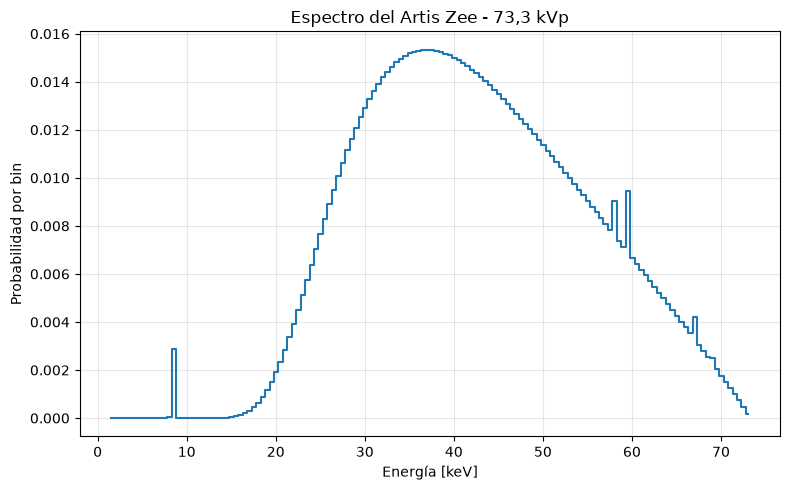

In [3]:

def read_spekpy_spectrum(filename):
    filename = Path(filename)

    if not filename.exists():
        raise FileNotFoundError(
            "No se encontró el archivo de espectro.\n"
            f"Ruta buscada: {filename.resolve()}"
        )

    energies = []
    fluences = []

    with open(filename, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            # Admite espacios o tabulaciones.
            # También admite coma decimal.
            parts = line.replace(",", ".").split()

            if len(parts) < 2:
                continue

            try:
                energy = float(parts[0])
                fluence = float(parts[1])
            except ValueError:
                # Encabezados/comentarios.
                continue

            # Se conservan también bins de fluencia cero.
            if energy > 0 and fluence >= 0:
                energies.append(energy)
                fluences.append(fluence)

    energies = np.asarray(energies, dtype=float)
    fluences = np.asarray(fluences, dtype=float)

    if energies.size == 0:
        raise ValueError(
            "No se encontraron dos columnas numéricas válidas "
            "en el archivo de SpekPy."
        )

    if np.sum(fluences) <= 0:
        raise ValueError(
            "La suma de las fluencias del espectro es cero."
        )

    # La tabla de SpekPy representa fluencia diferencial.
    # La multiplicación por dE hace el lector compatible también
    # con un espaciado energético no perfectamente uniforme.
    dE = np.gradient(energies)

    weights = fluences * dE
    weights = weights / np.sum(weights)

    return energies, weights, fluences


energies_keV, spectrum_weights, spectrum_fluences = (
    read_spekpy_spectrum(SPECTRUM_FILE)
)

mean_energy_from_file = np.sum(
    energies_keV * spectrum_weights
)

print("Espectro encontrado:", SPECTRUM_FILE.resolve())
print("Número de bins:", len(energies_keV))
print("Energía mínima:", energies_keV.min(), "keV")
print("Energía máxima:", energies_keV.max(), "keV")
print("Suma de probabilidades:", spectrum_weights.sum())
print("Energía media calculada:", mean_energy_from_file, "keV")
print("Energía media SpekPy esperada:", SPEKPY_MEAN_ENERGY_KEV, "keV")

if energies_keV.max() > TUBE_VOLTAGE_KV + 1.0:
    print(
        "ADVERTENCIA: la energía máxima supera de forma "
        "inesperada el kVp configurado."
    )


plt.figure(figsize=(8, 5))
plt.step(
    energies_keV,
    spectrum_weights,
    where="mid"
)
plt.xlabel("Energía [keV]")
plt.ylabel("Probabilidad por bin")
plt.title("Espectro del Artis Zee - 73,3 kVp")
plt.grid(alpha=0.3)
plt.tight_layout()

if SAVE_FIGURES:
    plt.savefig(
        FIGURE_DIR / "01_espectro_80kVp.png",
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )

plt.show()


## 4. Geometría del haz y normalización de referencia

Se calculan la orientación LAO, la posición del foco y del receptor, la apertura angular del haz y la posición del IRP. El signo de `LAO_DEG` responde al sistema de coordenadas definido en el modelo.


In [4]:

# ============================================================
# ROTACIÓN LAO
# ============================================================

R_lao = Rotation.from_euler(
    "y",
    LAO_DEG,
    degrees=True
)

beam_direction = R_lao.apply(
    np.array([0.0, 0.0, 1.0])
)


# ============================================================
# FOCO E ISOCENTRO
# ============================================================

source_position = (
    -SOURCE_TO_ISOCENTER_CM
    * cm
    * beam_direction
)

ISO_TO_DETECTOR_CM = (
    SID_CM - SOURCE_TO_ISOCENTER_CM
)

detector_position = (
    ISO_TO_DETECTOR_CM
    * cm
    * beam_direction
)


# ============================================================
# APERTURA REAL DEL HAZ
# ============================================================
#
# Se usa el campo REAL medido de 20.74 cm a 100 cm.
# No se vuelve a sobrescribir theta_max con el FOV nominal.

theta_max = np.arctan(
    (FIELD_MEASURED_CM / 2)
    / FIELD_REFERENCE_DISTANCE_CM
) * gate.g4_units.rad

field_iso_cm = (
    2.0
    * SOURCE_TO_ISOCENTER_CM
    * np.tan(theta_max)
)


# ============================================================
# IRP Y Ka,r DE REFERENCIA
# ============================================================

IRP_FROM_ISOCENTER_TOWARD_SOURCE_CM = 15.0

IRP_SOURCE_DISTANCE_CM = (
    SOURCE_TO_ISOCENTER_CM
    - IRP_FROM_ISOCENTER_TOWARD_SOURCE_CM
)

KA_R_SPEKPY_MGY = (
    SPEKPY_KERMA_UGY_PER_MAS
    * MAS
    * (
        SPEKPY_REFERENCE_DISTANCE_CM
        / IRP_SOURCE_DISTANCE_CM
    )**2
    / 1000.0
)

if KA_R_MEASURED_MGY is None:
    KA_R_REFERENCE_MGY = KA_R_SPEKPY_MGY
    KA_R_REFERENCE_SOURCE = "SpekPy (estimación del modelo)"
else:
    KA_R_REFERENCE_MGY = float(KA_R_MEASURED_MGY)
    KA_R_REFERENCE_SOURCE = "CAREreport/RDSR o medición"


print("Dirección central del haz:", beam_direction)
print("Posición del foco [cm]:", source_position / cm)
print("Posición del detector [cm]:", detector_position / cm)
print("SID calculada [cm]:",
      np.linalg.norm(detector_position - source_position) / cm)
print("Semiángulo del haz [°]:", theta_max / deg)
print("Campo estimado en isocentro [cm]:", field_iso_cm)
print("Distancia foco-IRP [cm]:", IRP_SOURCE_DISTANCE_CM)
print("Ka,r de referencia [mGy]:", KA_R_REFERENCE_MGY)
print("Fuente de normalización:", KA_R_REFERENCE_SOURCE)


Dirección central del haz: [-0.57357644  0.          0.81915204]
Posición del foco [cm]: [ 45.02575025  -0.         -64.30343548]
Posición del detector [cm]: [-14.62619913   0.          20.88837713]
SID calculada [cm]: 104.0
Semiángulo del haz [°]: 5.9204107652608124
Campo estimado en isocentro [cm]: 16.2809
Distancia foco-IRP [cm]: 63.5
Ka,r de referencia [mGy]: 2.6920483987227963
Fuente de normalización: SpekPy (estimación del modelo)


## 5. Fantoma antropomórfico simplificado y materiales

El torso del CIRS se representa mediante geometrías simples y materiales equivalentes para tejido blando, pulmón y hueso. Esta simplificación se mantiene explícita como una limitación del modelo.


In [5]:

# ============================================================
# FANTOMA CIRS ATOM 702 - MODELO TORÁCICO SIMPLIFICADO
# ============================================================

THORAX_WIDTH_CM = 25.0
THORAX_LENGTH_CM = 30.0
THORAX_AP_CM = 20.0

PHANTOM_CENTER_X_CM = 0.0
PHANTOM_CENTER_Y_CM = 0.0


def add_cirs_702_materials(sim):

    g_cm3 = gate.g4_units.g_cm3
    db = sim.volume_manager.material_database

    def normalize(weights):
        weights = np.asarray(weights, dtype=float)
        return (weights / np.sum(weights)).tolist()

    # Tejido blando
    db.add_material_weights(
        "CIRS_SoftTissue",
        ["H", "C", "N", "O", "Mg", "Cl"],
        normalize([
            8.47,
            57.44,
            1.65,
            24.59,
            7.62,
            0.19
        ]),
        1.055 * g_cm3
    )

    # Pulmón
    db.add_material_weights(
        "CIRS_Lung",
        ["H", "C", "N", "O", "Cl", "Ca"],
        normalize([
            8.59,
            65.89,
            3.52,
            19.29,
            1.69,
            1.01
        ]),
        0.202 * g_cm3
    )

    # Hueso
    db.add_material_weights(
        "CIRS_Bone",
        ["H", "C", "N", "O", "Mg", "Cl", "Ca"],
        normalize([
            4.83,
            37.03,
            0.97,
            35.66,
            6.19,
            0.05,
            15.24
        ]),
        1.517 * g_cm3
    )


PHANTOM_CENTER_Z_CM = (
    TABLE_TOP_Z_CM + THORAX_AP_CM / 2
)

print(
    "Centro del torso [cm]:",
    (
        PHANTOM_CENTER_X_CM,
        PHANTOM_CENTER_Y_CM,
        PHANTOM_CENTER_Z_CM,
    )
)
print(
    "Rango vertical aproximado del torso [cm]:",
    (
        PHANTOM_CENTER_Z_CM - THORAX_AP_CM / 2,
        PHANTOM_CENTER_Z_CM + THORAX_AP_CM / 2,
    )
)
print("Plano de medición z [cm]:", DOSIMETER_Z_CM)


Centro del torso [cm]: (0.0, 0.0, -9.0)
Rango vertical aproximado del torso [cm]: (-19.0, 1.0)
Plano de medición z [cm]: 16.0


## 6. Funciones auxiliares y comprobaciones geométricas


In [6]:

def get_point_xyz(point):
    """Devuelve [x_cm, y_cm, z_cm] para un punto experimental."""

    if isinstance(point, dict):
        x = float(point["x_cm"])
        y = float(point["y_cm"])
        z = float(
            point.get(
                "z_cm",
                DOSIMETER_Z_CM
            )
        )
        return np.array([x, y, z], dtype=float)

    point = np.asarray(point, dtype=float)

    if point.size != 3:
        raise ValueError(
            "Cada punto debe contener x, y, z."
        )

    return point



def validate_configuration():
    problems = []

    if ROOM_SIZE_X_CM <= 0:
        problems.append("ROOM_SIZE_X_CM debe ser > 0.")
    if ROOM_SIZE_Y_CM <= 0:
        problems.append("ROOM_SIZE_Y_CM debe ser > 0.")
    if ROOM_SIZE_Z_CM <= 0:
        problems.append("ROOM_SIZE_Z_CM debe ser > 0.")

    floor_z = -ISOCENTER_TO_FLOOR_CM
    ceiling_z = floor_z + ROOM_SIZE_Z_CM

    if not (floor_z <= DOSIMETER_Z_CM <= ceiling_z):
        problems.append(
            "La altura del dosímetro queda fuera de la sala."
        )

    for name, point in MEASUREMENT_POINTS.items():
        xyz = get_point_xyz(point)

        if abs(xyz[0]) > ROOM_SIZE_X_CM / 2:
            problems.append(
                f"{name}: x queda fuera del mapa."
            )

        if abs(xyz[1]) > ROOM_SIZE_Y_CM / 2:
            problems.append(
                f"{name}: y queda fuera del mapa."
            )

    if problems:
        print("ADVERTENCIAS DE CONFIGURACIÓN:")
        for p in problems:
            print(" -", p)
    else:
        print("Configuración geométrica básica: OK")

    if not MEASUREMENT_POINTS:
        print(
            "PENDIENTE: agregar los puntos experimentales "
            "en MEASUREMENT_POINTS."
        )


validate_configuration()


Configuración geométrica básica: OK


## 7. Construcción de la simulación principal

Incluye sala de aire, mesa equivalente, blindaje posterior del receptor, fantoma simplificado, fuente polienergética, `TLEDoseActor` para la malla y los puntos de medición, y `PhaseSpaceActor` en cada punto para el cálculo posterior de $H^*(10)$.


In [7]:

def build_simulation():

    sim = gate.Simulation()

    # --------------------------------------------------------
    # CONFIGURACIÓN GENERAL
    # --------------------------------------------------------

    sim.output_dir = MAIN_OUTPUT_DIR
    sim.number_of_threads = N_THREADS

    sim.g4_verbose = False
    sim.progress_bar = True
    sim.check_volumes_overlap = True
    sim.random_seed = "auto"

    # --------------------------------------------------------
    # MUNDO
    # --------------------------------------------------------
    #
    # La sala se representa como aire. Las paredes todavía no
    # se modelan como materiales, por lo que las dimensiones
    # controlan principalmente la extensión espacial del mapa.

    floor_z_cm = -ISOCENTER_TO_FLOOR_CM
    ceiling_z_cm = floor_z_cm + ROOM_SIZE_Z_CM

    world_z_half_extent_cm = (
        max(
            abs(floor_z_cm),
            abs(ceiling_z_cm),
            abs(source_position[2] / cm)
        )
        + WORLD_MARGIN_CM
    )

    world = sim.world

    world.size = [
        (ROOM_SIZE_X_CM + 2 * WORLD_MARGIN_CM) * cm,
        (ROOM_SIZE_Y_CM + 2 * WORLD_MARGIN_CM) * cm,
        (2 * world_z_half_extent_cm) * cm,
    ]

    world.material = "G4_AIR"

    # --------------------------------------------------------
    # MATERIALES
    # --------------------------------------------------------

    add_cirs_702_materials(sim)

    # --------------------------------------------------------
    # MESA
    # --------------------------------------------------------

    table = sim.add_volume(
        "Box",
        "table"
    )

    table.size = [
        TABLE_WIDTH_CM * cm,
        TABLE_LENGTH_CM * cm,
        TABLE_EQ_AL_THICKNESS_MM * mm,
    ]

    table_center_z = (
        TABLE_TOP_Z_CM * cm
        - (TABLE_EQ_AL_THICKNESS_MM * mm) / 2
    )

    table.translation = [
        0,
        0,
        table_center_z
    ]

    table.material = "G4_Al"

    # ============================================================
    # BLINDAJE POSTERIOR DEL RECEPTOR
    # ============================================================
    
    lead_backing = sim.add_volume(
        "Box",
        "detector_lead_backing"
    )
    
    lead_backing.material = "G4_Pb"
    
    lead_backing.size = [
        LEAD_BACKING_WIDTH_CM * cm,
        LEAD_BACKING_HEIGHT_CM * cm,
        LEAD_BACKING_THICKNESS_MM * mm,
    ]
    
    # La placa debe ser perpendicular al eje del haz
    lead_backing.rotation = R_lao.as_matrix()
    
    # Centro de la placa a 30 cm del isocentro
    lead_backing.translation = (
        LEAD_BACKING_DISTANCE_ISO_CM
        * cm
        * beam_direction
    )
        
    # --------------------------------------------------------
    # FANTOMA CIRS ATOM 702 SIMPLIFICADO
    # --------------------------------------------------------

    phantom_center_x = PHANTOM_CENTER_X_CM * cm
    phantom_center_y = PHANTOM_CENTER_Y_CM * cm
    phantom_center_z = PHANTOM_CENTER_Z_CM * cm

    # TORSO

    torso = sim.add_volume(
        "Ellipsoid",
        "phantom_torso"
    )

    torso.xSemiAxis = THORAX_WIDTH_CM / 2 * cm
    torso.ySemiAxis = THORAX_LENGTH_CM / 2 * cm
    torso.zSemiAxis = THORAX_AP_CM / 2 * cm

    torso.translation = [
        phantom_center_x,
        phantom_center_y,
        phantom_center_z
    ]

    torso.material = "CIRS_SoftTissue"

    # PULMÓN IZQUIERDO

    lung_left = sim.add_volume(
        "Ellipsoid",
        "lung_left"
    )

    lung_left.mother = torso.name
    lung_left.xSemiAxis = 3.8 * cm
    lung_left.ySemiAxis = 8.5 * cm
    lung_left.zSemiAxis = 5.5 * cm

    lung_left.translation = [
        +4.5 * cm,
        0.0 * cm,
        +0.8 * cm
    ]

    lung_left.material = "CIRS_Lung"

    # PULMÓN DERECHO

    lung_right = sim.add_volume(
        "Ellipsoid",
        "lung_right"
    )

    lung_right.mother = torso.name
    lung_right.xSemiAxis = 3.8 * cm
    lung_right.ySemiAxis = 8.5 * cm
    lung_right.zSemiAxis = 5.5 * cm

    lung_right.translation = [
        -4.5 * cm,
        0.0 * cm,
        +0.8 * cm
    ]

    lung_right.material = "CIRS_Lung"

    # COLUMNA

    spine = sim.add_volume(
        "Tubs",
        "spine"
    )

    spine.mother = torso.name
    spine.rmin = 0.0 * cm
    spine.rmax = 1.3 * cm
    spine.dz = 10.0 * cm

    spine.rotation = Rotation.from_euler(
        "x",
        90,
        degrees=True
    ).as_matrix()

    spine.translation = [
        0.0 * cm,
        0.0 * cm,
        -5.8 * cm
    ]

    spine.material = "CIRS_Bone"

    # ESTERNÓN

    sternum = sim.add_volume(
        "Box",
        "sternum"
    )

    sternum.mother = torso.name

    sternum.size = [
        2.0 * cm,
        15.0 * cm,
        1.0 * cm
    ]

    sternum.translation = [
        0.0 * cm,
        0.0 * cm,
        +7.2 * cm
    ]

    sternum.material = "CIRS_Bone"

    # --------------------------------------------------------
    # SOPORTE LOCAL DE LA FUENTE
    # --------------------------------------------------------

    source_frame = sim.add_volume(
        "Box",
        "source_frame"
    )

    source_frame.size = [
        1 * mm,
        1 * mm,
        1 * mm
    ]

    source_frame.material = "G4_AIR"
    source_frame.translation = source_position
    source_frame.rotation = R_lao.as_matrix()

    # --------------------------------------------------------
    # FUENTE DE RAYOS X
    # --------------------------------------------------------

    source = sim.add_source(
        "GenericSource",
        "artis_zee_source"
    )

    source.attached_to = source_frame.name
    source.particle = "gamma"

    source.position.type = "point"
    source.position.translation = [0, 0, 0]

    source.direction.type = "iso"
    
    source.direction.theta = [
        180 * deg - theta_max,
        180 * deg
    ]
    
    source.direction.phi = [
        0 * deg,
        360 * deg
    ]
    
    source.direction_relative_to_attached_volume = True

    source.energy.type = "spectrum_discrete"
    source.energy.spectrum_energies = (
        energies_keV * keV
    ).tolist()
    source.energy.spectrum_weights = (
        spectrum_weights
    ).tolist()

    # La versión instalada reconoce source.n.
    source.n = int(N_PRIMARIES_PER_THREAD)

    # --------------------------------------------------------
    # FÍSICA
    # --------------------------------------------------------

    sim.physics_manager.physics_list_name = (
        "G4EmLivermorePhysics"
    )

    sim.physics_manager.set_production_cut(
        "world",
        "gamma",
        1 * mm
    )

    sim.physics_manager.set_production_cut(
        "world",
        "electron",
        1 * mm
    )

    phantom_volume_names = [
        torso.name,
        lung_left.name,
        lung_right.name,
        spine.name,
        sternum.name,
    ]

    for volume_name in phantom_volume_names:
        sim.physics_manager.set_production_cut(
            volume_name,
            "gamma",
            0.1 * mm
        )
        sim.physics_manager.set_production_cut(
            volume_name,
            "electron",
            0.1 * mm
        )

    sim.physics_manager.set_production_cut(
        table.name,
        "gamma",
        0.1 * mm
    )

    sim.physics_manager.set_production_cut(
        table.name,
        "electron",
        0.1 * mm
    )

    # --------------------------------------------------------
    # LIMITACIÓN DEL STEP EN AIRE
    # --------------------------------------------------------
    
    sim.physics_manager.user_limits_particles = [
        "gamma"
    ]
    
    sim.physics_manager.set_max_step_size(
        "world",
        MAX_STEP_AIR_CM * cm
    )
        
    # --------------------------------------------------------
    # MAPA DE DOSIS EN AIRE
    # --------------------------------------------------------

    nx = int(
        np.ceil(
            ROOM_SIZE_X_CM / ROOM_VOXEL_CM
        )
    )

    ny = int(
        np.ceil(
            ROOM_SIZE_Y_CM / ROOM_VOXEL_CM
        )
    )

    room_dx_cm = ROOM_SIZE_X_CM / nx
    room_dy_cm = ROOM_SIZE_Y_CM / ny

    room_dose = sim.add_actor(
        "TLEDoseActor",
        "room_dose"
    )

    room_dose.attached_to = "world"

    room_dose.size = [
        nx,
        ny,
        1
    ]

    room_dose.spacing = [
        room_dx_cm * cm,
        room_dy_cm * cm,
        ROOM_PLANE_THICKNESS_CM * cm
    ]

    room_dose.translation = [
        0,
        0,
        DOSIMETER_Z_CM * cm
    ]

    room_dose.database = "EPDL"

    # Solo necesitamos dosis e incertidumbre.
    room_dose.edep.active = False
    room_dose.dose.active = True
    room_dose.dose_uncertainty.active = True
    room_dose.dose_squared.active = True

    room_dose.dose.output_filename = (
        "room_dose_xy.mhd"
    )

    room_dose.dose_uncertainty.output_filename = (
        "room_dose_xy_uncertainty.mhd"
    )

    room_dose.counts.active = True
    room_dose.counts.output_filename = "room_counts.mhd"
    
    # --------------------------------------------------------
    # PUNTOS EXPERIMENTALES
    # --------------------------------------------------------
    
    point_actors = {}
    point_volumes = {}
    hstar_phsp_actors = {}
    

    
    for point_name, point_info in MEASUREMENT_POINTS.items():
    
        xyz_cm = get_point_xyz(
            point_info
        )
    
        # ========================================================
        # VOLUMEN FÍSICO DE AIRE
        # ========================================================
    
        point_volume = sim.add_volume(
            "Box",
            f"detector_{point_name}"
        )
    
        point_volume.size = [
            POINT_SCORING_SIZE_CM * cm,
            POINT_SCORING_SIZE_CM * cm,
            POINT_SCORING_SIZE_CM * cm
        ]
    
        point_volume.translation = [
            xyz_cm[0] * cm,
            xyz_cm[1] * cm,
            xyz_cm[2] * cm
        ]
    
        point_volume.material = "G4_AIR"
    
        # ========================================================
        # TLE DOSE ACTOR
        # ========================================================
    
        point_actor = sim.add_actor(
            "TLEDoseActor",
            f"dose_{point_name}"
        )
    
        point_actor.attached_to = (
            point_volume.name
        )
    
        point_actor.size = [
            1,
            1,
            1
        ]
    
        point_actor.spacing = [
            POINT_SCORING_SIZE_CM * cm,
            POINT_SCORING_SIZE_CM * cm,
            POINT_SCORING_SIZE_CM * cm
        ]
    
        point_actor.translation = [
            0,
            0,
            0
        ]
    
        point_actor.database = "EPDL"
    
        point_actor.dose.active = True
        point_actor.dose_squared.active = True
        point_actor.dose_uncertainty.active = True
        point_actor.edep.active = True
    
        point_actor.dose.output_filename = (
            f"{point_name}_dose.mhd"
        )
    
        point_actor.edep.output_filename = (
            f"{point_name}_edep.mhd"
        )
    
        point_actor.dose_uncertainty.output_filename = (
            f"{point_name}_uncertainty.mhd"
        )
    
        # ========================================================
        # PHASE SPACE PARA H*(10)
        # ========================================================
    
        phsp_actor = sim.add_actor(
            "PhaseSpaceActor",
            f"phsp_hstar_{point_name}"
        )
        
        phsp_actor.attached_to = (
            point_volume.name
        )
        
        phsp_actor.steps_to_store = "all"
        
        phsp_actor.attributes = [
            "EventID",
            "ParticleName",
            "PreKineticEnergy",
            "StepLength",
        ]
        
        phsp_actor.output_filename = (
            f"{point_name}_hstar_phase_space.root"
        )
    
    
        # ========================================================
        # GUARDAR ACTORES
        # ========================================================
    
        point_actors[
            point_name
        ] = point_actor
    
        point_volumes[
            point_name
        ] = point_volume
    
        hstar_phsp_actors[
            point_name
        ] = phsp_actor
    
    # --------------------------------------------------------
    # ESTADÍSTICAS
    # --------------------------------------------------------

    stats = sim.add_actor(
        "SimulationStatisticsActor",
        "Stats"
    )

    stats.track_types_flag = True
    stats.output_filename = "statistics.txt"

    
    
    return (
        sim,
        source,
        torso,
        table,
        room_dose,
        point_actors,
        hstar_phsp_actors,
        stats
    )


## 8. Simulación independiente de normalización en el IRP

Esta simulación calcula la respuesta por primario en el IRP mediante `TLEDoseActor` y registra el cruce de fotones mediante `PhaseSpaceActor`. La geometría del IRP se mantiene separada de los detectores ocupacionales.


In [8]:
def build_air_kerma_simulation():

    sim = gate.Simulation()

    sim.output_dir = NORM_OUTPUT_DIR
    sim.number_of_threads = N_THREADS

    sim.g4_verbose = False
    sim.progress_bar = True
    sim.check_volumes_overlap = True
    sim.random_seed = "auto"

    # --------------------------------------------------------
    # MUNDO
    # --------------------------------------------------------

    world = sim.world

    world.size = [
        3 * m,
        3 * m,
        3 * m
    ]

    world.material = "G4_AIR"

    # --------------------------------------------------------
    # SOPORTE LOCAL DE LA FUENTE
    # --------------------------------------------------------

    source_frame = sim.add_volume(
        "Box",
        "source_frame_norm"
    )

    source_frame.size = [
        1 * mm,
        1 * mm,
        1 * mm
    ]

    source_frame.material = "G4_AIR"

    source_frame.translation = (
        source_position
    )

    source_frame.rotation = (
        R_lao.as_matrix()
    )

    # --------------------------------------------------------
    # FUENTE
    # --------------------------------------------------------

    source = sim.add_source(
        "GenericSource",
        "artis_zee_source_norm"
    )

    source.attached_to = (
        source_frame.name
    )

    source.particle = "gamma"

    source.position.type = "point"

    source.position.translation = [
        0,
        0,
        0
    ]

    # Haz cónico
    source.direction.type = "iso"
    
    source.direction.theta = [
        180 * deg - theta_max,
        180 * deg
    ]
    
    source.direction.phi = [
        0 * deg,
        360 * deg
    ]
    
    source.direction_relative_to_attached_volume = True

    # --------------------------------------------------------
    # ESPECTRO
    # --------------------------------------------------------

    source.energy.type = (
        "spectrum_discrete"
    )

    source.energy.spectrum_energies = (
        energies_keV * keV
    ).tolist()

    source.energy.spectrum_weights = (
        spectrum_weights
    ).tolist()

    # --------------------------------------------------------
    # HISTORIAS
    # --------------------------------------------------------

    source.n = int(
        N_PRIMARIES_PER_THREAD_NORMALIZATION
    )

    # --------------------------------------------------------
    # FÍSICA
    # --------------------------------------------------------

    sim.physics_manager.physics_list_name = (
        "G4EmLivermorePhysics"
    )

    sim.physics_manager.set_production_cut(
        "world",
        "gamma",
        1 * mm
    )

    sim.physics_manager.set_production_cut(
        "world",
        "electron",
        1 * mm
    )

    # --------------------------------------------------------
    # LIMITACIÓN DEL STEP EN EL AIRE
    # --------------------------------------------------------

    sim.physics_manager.user_limits_particles = [
        "gamma"
    ]

    sim.physics_manager.set_max_step_size(
        "world",
        MAX_STEP_AIR_CM * cm
    )

    # --------------------------------------------------------
    # POSICIÓN DEL IRP
    # --------------------------------------------------------

    irp_position = (
        -IRP_FROM_ISOCENTER_TOWARD_SOURCE_CM
        * cm
        * beam_direction
    )

    print(
        "IRP [cm] =",
        irp_position / cm
    )

    print(
        "Distancia foco-IRP [cm] =",
        np.linalg.norm(
            irp_position - source_position
        ) / cm
    )

    # --------------------------------------------------------
    # VOLUMEN FÍSICO DE AIRE EN EL IRP
    # --------------------------------------------------------

    irp_detector = sim.add_volume(
        "Box",
        "irp_air_detector"
    )

    irp_detector.size = [
        IRP_DETECTOR_WIDTH_CM * cm,
        IRP_DETECTOR_WIDTH_CM * cm,
        IRP_DETECTOR_THICKNESS_CM * cm
    ]
    
    irp_detector.translation = (
        irp_position.tolist()
    )
    
    irp_detector.rotation = (
        R_lao.as_matrix()
    )
    irp_detector.material = "G4_AIR"

    irp_detector.color = [
        1.0,
        0.0,
        0.0,
        0.7
    ]

    # ============================================================
    # TLE DOSE ACTOR
    # ============================================================

    irp_dose = sim.add_actor(
        "TLEDoseActor",
        "irp_air_dose"
    )

    irp_dose.attached_to = (
        irp_detector.name
    )

    irp_dose.size = [
        1,
        1,
        1
    ]

    irp_dose.spacing = [
        IRP_DETECTOR_WIDTH_CM * cm,
        IRP_DETECTOR_WIDTH_CM * cm,
        IRP_DETECTOR_THICKNESS_CM * cm
    ]

    irp_dose.translation = [
        0,
        0,
        0
    ]

    irp_dose.database = "EPDL"

    # --------------------------------------------------------
    # SALIDAS TLE
    # --------------------------------------------------------

    irp_dose.dose.active = True
    irp_dose.dose_squared.active = True
    irp_dose.dose_uncertainty.active = True
    irp_dose.edep.active = True

    irp_dose.dose.output_filename = (
        "irp_air_dose.mhd"
    )

    irp_dose.edep.output_filename = (
        "irp_air_edep.mhd"
    )

    irp_dose.dose_uncertainty.output_filename = (
        "irp_air_dose_uncertainty.mhd"
    )

    # ============================================================
    # PHASE SPACE ACTOR DIRECTAMENTE EN EL IRP
    # ============================================================

    phsp_irp = sim.add_actor(
        "PhaseSpaceActor",
        "phsp_irp"
    )

    phsp_irp.attached_to = (
        irp_detector.name
    )

    # Guardar únicamente partículas al entrar
    # al volumen del IRP.
    phsp_irp.steps_to_store = "entering"

    phsp_irp.attributes = [
        "EventID",
        "TrackID",
        "ParticleName",
        "KineticEnergy",
        "PrePosition",
        "PreDirection",
    ]

    phsp_irp.output_filename = (
        "irp_phase_space.root"
    )


    # --------------------------------------------------------
    # ESTADÍSTICAS
    # --------------------------------------------------------

    stats = sim.add_actor(
        "SimulationStatisticsActor",
        "Stats_Normalization"
    )

    stats.track_types_flag = True

    stats.output_filename = (
        "statistics_normalization.txt"
    )

    # --------------------------------------------------------
    # RETORNO
    # --------------------------------------------------------

    return (
        sim,
        source,
        irp_detector,
        irp_dose,
        phsp_irp,
        stats
    )

## 9. Verificación visual de la geometría


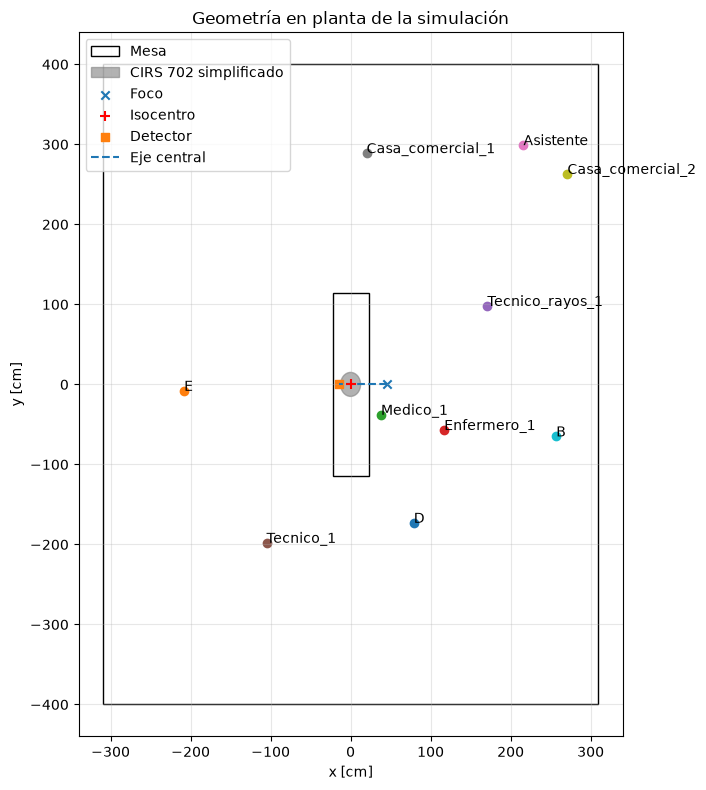

In [9]:

def plot_geometry_top_view():

    fig, ax = plt.subplots(
        figsize=(8, 8)
    )

    # Sala
    room = Rectangle(
        (
            -ROOM_SIZE_X_CM / 2,
            -ROOM_SIZE_Y_CM / 2
        ),
        ROOM_SIZE_X_CM,
        ROOM_SIZE_Y_CM,
        fill=False,
    )

    ax.add_patch(room)

    # Mesa
    table_patch = Rectangle(
        (
            -TABLE_WIDTH_CM / 2,
            -TABLE_LENGTH_CM / 2
        ),
        TABLE_WIDTH_CM,
        TABLE_LENGTH_CM,
        fill=False,
        label="Mesa"
    )

    ax.add_patch(table_patch)

    # Torso
    torso_patch = Ellipse(
        (
            PHANTOM_CENTER_X_CM,
            PHANTOM_CENTER_Y_CM
        ),
        THORAX_WIDTH_CM,
        THORAX_LENGTH_CM,
        fill=True,
        color="gray",
        alpha=0.6,
        label="CIRS 702 simplificado"
    )

    ax.add_patch(torso_patch)

    # Foco, isocentro y detector
    ax.scatter(
        source_position[0] / cm,
        source_position[1] / cm,
        marker="x",
        label="Foco"
    )

    ax.scatter(
        0,
        0,
        marker="+",
        color="red",
        s=50,
        zorder=5,
        label="Isocentro"
    )

    ax.scatter(
        detector_position[0] / cm,
        detector_position[1] / cm,
        marker="s",
        label="Detector"
    )

    ax.plot(
        [
            source_position[0] / cm,
            detector_position[0] / cm
        ],
        [
            source_position[1] / cm,
            detector_position[1] / cm
        ],
        linestyle="--",
        label="Eje central"
    )

    # Puntos experimentales
    for name, point_info in MEASUREMENT_POINTS.items():
        xyz = get_point_xyz(
            point_info
        )

        ax.scatter(
            xyz[0],
            xyz[1]
        )

        ax.annotate(
            name,
            (xyz[0], xyz[1])
        )

    ax.set_xlabel("x [cm]")
    ax.set_ylabel("y [cm]")
    ax.set_title(
        "Geometría en planta de la simulación"
    )
    ax.set_aspect("equal")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()

    if SAVE_FIGURES:
        plt.savefig(
            FIGURE_DIR / "02_geometria_planta.png",
            dpi=FIGURE_DPI,
            bbox_inches="tight"
        )

    plt.show()


plot_geometry_top_view()


## 10. Ejecución de las simulaciones



In [10]:


def read_mhd_array(filename):

    filename = Path(filename)

    if not filename.exists():
        raise FileNotFoundError(
            f"No se encontró el archivo: {filename}"
        )

    image = sitk.ReadImage(
        str(filename)
    )

    array = sitk.GetArrayFromImage(
        image
    )

    return array



# ============================================================
# SIMULACIÓN PRINCIPAL
# ============================================================

(
    sim,
    source,
    torso,
    table,
    room_dose,
    point_actors,
    hstar_phsp_actors,
    stats
) = build_simulation()


print("Árbol de volúmenes:")

try:
    print(
        sim.volume_manager.dump_volume_tree()
    )
except Exception:
    pass


# Ejecutar en proceso independiente
sim.run(
    start_new_process=True
)


print(
    "\nESTADÍSTICAS SIMULACIÓN PRINCIPAL"
)

print(stats)


# ============================================================
# SIMULACIÓN DE NORMALIZACIÓN
# ============================================================

(
    sim_norm,
    source_norm,
    irp_detector,
    irp_dose,
    phsp_irp,
    stats_norm
) = build_air_kerma_simulation()


# Ejecutar también en proceso independiente
sim_norm.run(
    start_new_process=True
)

print(
    "\nESTADÍSTICAS NORMALIZACIÓN"
)

print(stats_norm)


# ============================================================
# LECTURA DE RESULTADOS DEL IRP
# ============================================================

irp_dose_file = (
    NORM_OUTPUT_DIR
    / "irp_air_dose.mhd"
)

irp_edep_file = (
    NORM_OUTPUT_DIR
    / "irp_air_edep.mhd"
)

irp_uncertainty_file = (
    NORM_OUTPUT_DIR
    / "irp_air_dose_uncertainty.mhd"
)


# Leer los archivos MHD
irp_dose_array = read_mhd_array(
    irp_dose_file
)

irp_edep_array = read_mhd_array(
    irp_edep_file
)

irp_uncertainty_array = read_mhd_array(
    irp_uncertainty_file
)


# ============================================================
# EXTRAER EL ÚNICO VOXEL
# ============================================================

irp_dose_raw = float(
    np.squeeze(
        irp_dose_array
    )
)

irp_edep_raw = float(
    np.squeeze(
        irp_edep_array
    )
)

irp_uncertainty = float(
    np.squeeze(
        irp_uncertainty_array
    )
)


# ============================================================
# MOSTRAR RESULTADOS
# ============================================================

print("\nRESULTADOS DE NORMALIZACIÓN")

print(
    f"Dosis IRP MC [Gy] = "
    f"{irp_dose_raw:.6e}"
)

print(
    f"Edep IRP MC = "
    f"{irp_edep_raw:.6e}"
)

print(
    f"Incertidumbre relativa IRP = "
    f"{irp_uncertainty:.6e}"
)

print(
    f"Incertidumbre relativa IRP [%] = "
    f"{irp_uncertainty * 100:.2f} %"
)


# ============================================================
# COMPROBACIÓN
# ============================================================

if irp_dose_raw <= 0:

    if irp_edep_raw > 0:

        raise RuntimeError(
            "Se obtuvo energía depositada en el detector "
            "del IRP, pero la dosis es cero. "
            "Se debe revisar la configuración del TLEDoseActor."
        )

    else:

        raise RuntimeError(
            "La dosis y la energía depositada en el IRP "
            "son cero. El haz no está atravesando "
            "correctamente el detector de normalización."
        )


print(
    "\nNormalización IRP calculada correctamente."
)

Árbol de volúmenes:
volume_tree_root
    world
        table
        detector_lead_backing
        phantom_torso
            lung_left
            lung_right
            spine
            sternum
        source_frame
        detector_Medico_1
        detector_Enfermero_1
        detector_Tecnico_rayos_1
        detector_Tecnico_1
        detector_Asistente
        detector_Casa_comercial_1
        detector_Casa_comercial_2
        detector_B
        detector_D
        detector_E

Dispatching simulation to subprocess ...
Simulation: create RunManager (single thread)
Simulation: initialize Geometry
Simulation: initialize Physics
Simulation: initialize Sources
Simulation: initialize Auxiliary attributes
Simulation: initialize Actors
Simulation: initialize G4RunManager
Simulation: initialize PhysicsEngine
Simulation: initialize Chemistry
Simulation: initialize Actor-Source links
Simulation: register Actions of actors
Simulation: register Actions of auxiliary attributes
Simulation: check vo

## 11. Lectura de salidas y normalización absoluta

Se obtiene la respuesta del IRP por primario y el número equivalente de primarios asociado con el $K_{a,r}$ de referencia. Este factor se utiliza para escalar los resultados de la simulación principal.


In [11]:

def actor_image_to_array(output_interface):
    """Convierte la salida de imagen de un actor a NumPy."""

    # GATE 10 permite acceder a la imagen directamente
    # después de sim.run().
    try:
        image = output_interface.image

        if image is not None:
            return np.asarray(image)

    except Exception:
        pass

    # Alternativa: leer el archivo escrito en disco.
    try:
        import SimpleITK as sitk

        output_path = (
            output_interface.get_output_path()
        )

        image = sitk.ReadImage(
            str(output_path)
        )

        return sitk.GetArrayFromImage(
            image
        )

    except Exception as exc:
        raise RuntimeError(
            "No fue posible obtener la imagen del actor "
            "ni desde memoria ni desde disco."
        ) from exc


# ============================================================
# MAPA PRINCIPAL
# ============================================================

room_dose_raw = np.squeeze(
    actor_image_to_array(
        room_dose.dose
    )
)

room_uncertainty = np.squeeze(
    actor_image_to_array(
        room_dose.dose_uncertainty
    )
)


# ============================================================
# NORMALIZACIÓN EN EL IRP
# ============================================================

irp_dose_raw = float(
    np.squeeze(
        actor_image_to_array(
            irp_dose.dose
        )
    )
)

irp_uncertainty = float(
    np.squeeze(
        actor_image_to_array(
            irp_dose.dose_uncertainty
        )
    )
)

if irp_dose_raw <= 0:
    raise RuntimeError(
        "El actor de normalización obtuvo dosis cero "
        "en el IRP. Se debe revisar su posición/tamaño."
    )

# Resultado MC por primario:
irp_dose_per_primary_Gy = (
    irp_dose_raw
    / N_PRIMARIES_NORMALIZATION
)

room_dose_per_primary_Gy = (
    room_dose_raw
    / N_PRIMARIES
)

# Ka,r de referencia para la exposición real.
ka_r_reference_Gy = (
    KA_R_REFERENCE_MGY * 1e-3
)

# Número equivalente de primarios reales que producirían
# el Ka,r de referencia.
equivalent_real_primaries = (
    ka_r_reference_Gy
    / irp_dose_per_primary_Gy
)

# Dosis absorbida en aire / aproximación de kerma colisional
# para la exposición experimental completa.
room_dose_absolute_Gy = (
    room_dose_per_primary_Gy
    * equivalent_real_primaries
)

room_dose_absolute_uGy = (
    room_dose_absolute_Gy
    * 1e6
)

# Tasa equivalente de dosis absorbida en aire.
room_dose_rate_mGy_h = (
    room_dose_absolute_Gy
    * 1e3
    * 3600.0
    / EXPOSURE_TIME_S
)

room_uncertainty_percent = (
    room_uncertainty * 100.0
)


print("Ka,r usado [mGy]:", KA_R_REFERENCE_MGY)
print("Fuente:", KA_R_REFERENCE_SOURCE)
print("IRP MC por primario [Gy]:", irp_dose_per_primary_Gy)
print(
    "Incertidumbre relativa del IRP [%]:",
    irp_uncertainty * 100.0
)
print(
    "Máximo del mapa [uGy/exposición]:",
    np.nanmax(room_dose_absolute_uGy)
)


Ka,r usado [mGy]: 2.6920483987227963
Fuente: SpekPy (estimación del modelo)
IRP MC por primario [Gy]: 6.8616045974661e-15
Incertidumbre relativa del IRP [%]: 1.41048231452895
Máximo del mapa [uGy/exposición]: 66.97908758733172


## 12. Cálculo de $\dot H^*(10)$ y validación puntual

La fluencia se estima mediante longitud de trayectoria dentro de cada volumen de puntuación. Las contribuciones se ponderan con coeficientes de conversión fluencia--$H^*(10)$ y se agrupan por historia Monte Carlo para estimar la incertidumbre estadística. La comparación principal se realiza contra los valores experimentales en las mismas posiciones.


In [12]:


# ============================================================
# COEFICIENTES ICRP 74:
# H*(10) / fluencia para fotones
#
# Energía: MeV
# Coeficiente: pSv cm²
# ============================================================

HSTAR_ENERGY_MEV = np.array([
    0.010,
    0.015,
    0.020,
    0.030,
    0.040,
    0.050,
    0.060,
    0.080,
    0.100,
    0.150,
    0.200,
    0.300,
    0.400,
    0.500,
    0.600,
    0.800,
    1.000,
])

HSTAR_COEFF_PSV_CM2 = np.array([
    0.061,
    0.83,
    1.05,
    0.81,
    0.64,
    0.55,
    0.51,
    0.53,
    0.61,
    0.89,
    1.20,
    1.80,
    2.38,
    2.93,
    3.44,
    4.38,
    5.20,
])


# ============================================================
# INTERPOLACIÓN LOG-LOG
# ============================================================

def hstar_coeff_from_energy_mev(energy_mev):

    energy_mev = np.asarray(
        energy_mev,
        dtype=float
    )

    coeff = np.full(
        energy_mev.shape,
        np.nan,
        dtype=float
    )

    valid = (
        (energy_mev >= HSTAR_ENERGY_MEV.min())
        &
        (energy_mev <= HSTAR_ENERGY_MEV.max())
    )

    coeff[valid] = np.exp(
        np.interp(
            np.log(
                energy_mev[valid]
            ),
            np.log(
                HSTAR_ENERGY_MEV
            ),
            np.log(
                HSTAR_COEFF_PSV_CM2
            )
        )
    )

    return coeff


# ============================================================
# FUNCIÓN PARA UN PUNTO
# ============================================================

def calculate_hstar10_point(
    root_path,
    n_primaries,
    equivalent_real_primaries,
    exposure_time_s,
    scoring_size_cm,
):

    volume_cm3 = (
        scoring_size_cm ** 3
    )

    # --------------------------------------------------------
    # LEER PHASE SPACE
    # --------------------------------------------------------

    with uproot.open(root_path) as f:

        tree = f[f.keys()[0]]

        arrays = tree.arrays(
            [
                "EventID",
                "ParticleName",
                "PreKineticEnergy",
                "StepLength",
            ],
            library="np"
        )

    event_id = arrays["EventID"]
    particle = arrays["ParticleName"]
    energy_mev = arrays["PreKineticEnergy"]
    step_length_mm = arrays["StepLength"]

    # --------------------------------------------------------
    # NORMALIZAR ParticleName A STRING
    # --------------------------------------------------------

    particle_str = np.array([
        (
            p.decode()
            if isinstance(p, bytes)
            else str(p)
        )
        for p in particle
    ])

    # --------------------------------------------------------
    # SOLO GAMMAS
    # --------------------------------------------------------

    gamma_mask = (
        particle_str == "gamma"
    )

    event_id = event_id[
        gamma_mask
    ]

    energy_mev = energy_mev[
        gamma_mask
    ]

    step_length_mm = step_length_mm[
        gamma_mask
    ]

    # --------------------------------------------------------
    # CONVERSIÓN mm -> cm
    # --------------------------------------------------------

    step_length_cm = (
        step_length_mm
        / 10.0
    )

    # --------------------------------------------------------
    # COEFICIENTES H*(10)
    # --------------------------------------------------------

    h_coeff = (
        hstar_coeff_from_energy_mev(
            energy_mev
        )
    )

    # --------------------------------------------------------
    # EVENTOS FUERA DE RANGO
    # --------------------------------------------------------

    valid = (
        np.isfinite(h_coeff)
        &
        np.isfinite(step_length_cm)
        &
        (step_length_cm > 0)
    )

    n_gamma_total = len(
        energy_mev
    )

    n_gamma_valid = np.sum(
        valid
    )

    fraction_valid = (
        n_gamma_valid
        / n_gamma_total
        if n_gamma_total > 0
        else np.nan
    )

    event_id = event_id[
        valid
    ]

    step_length_cm = (
        step_length_cm[
            valid
        ]
    )

    h_coeff = h_coeff[
        valid
    ]

    energy_valid_mev = (
        energy_mev[
            valid
        ]
    )

    # ========================================================
    # ESTIMADOR DE FLUENCIA POR LONGITUD DE TRAYECTORIA
    #
    # Phi = sum(L) / V
    #
    # Contribución:
    #
    # (cm / cm³) * (pSv cm²) = pSv
    # ========================================================

    hstar_step_pSv = (
        step_length_cm
        / volume_cm3
        * h_coeff
    )

    # ========================================================
    # SUMA POR HISTORIA MONTE CARLO
    # ========================================================

    unique_events, inverse = np.unique(
        event_id,
        return_inverse=True
    )

    hstar_per_event_pSv = np.bincount(
        inverse,
        weights=hstar_step_pSv
    )

    # --------------------------------------------------------
    # SUMA TOTAL DE LA CORRIDA
    # --------------------------------------------------------

    S1 = np.sum(
        hstar_per_event_pSv
    )

    S2 = np.sum(
        hstar_per_event_pSv ** 2
    )

    N = float(
        n_primaries
    )

    # ========================================================
    # H*(10) POR PRIMARIO
    # ========================================================

    hstar_per_primary_pSv = (
        S1 / N
    )

    # ========================================================
    # INCERTIDUMBRE ESTADÍSTICA
    #
    # Se incluyen implícitamente las historias con contribución 0.
    # ========================================================

    if N > 1 and S1 > 0:

        sample_variance = (
            S2
            - (S1 ** 2) / N
        ) / (
            N - 1
        )

        sample_variance = max(
            sample_variance,
            0.0
        )

        standard_error_mean = np.sqrt(
            sample_variance
            / N
        )

        relative_uncertainty = (
            standard_error_mean
            / hstar_per_primary_pSv
        )

    else:

        relative_uncertainty = np.nan

    # ========================================================
    # ESCALADO A LA EXPOSICIÓN REAL
    # ========================================================

    hstar_real_pSv = (
        hstar_per_primary_pSv
        * equivalent_real_primaries
    )

    # pSv -> mSv
    hstar_real_mSv = (
        hstar_real_pSv
        * 1e-9
    )

    # ========================================================
    # TASA H*(10)
    # ========================================================

    hstar_rate_mSv_h = (
        hstar_real_mSv
        * 3600.0
        / exposure_time_s
    )

    return {

        "Hstar_per_primary_pSv":
            hstar_per_primary_pSv,

        "Hstar_real_mSv":
            hstar_real_mSv,

        "Hstar_rate_mSv_h":
            hstar_rate_mSv_h,

        "u_MC_percent":
            relative_uncertainty
            * 100.0,

        "N_gamma_total":
            n_gamma_total,

        "N_gamma_valid":
            n_gamma_valid,

        "fraction_valid":
            fraction_valid,

        "energy_min_keV":
            (
                np.min(
                    energy_valid_mev
                )
                * 1000.0
                if len(
                    energy_valid_mev
                ) > 0
                else np.nan
            ),

        "energy_max_keV":
            (
                np.max(
                    energy_valid_mev
                )
                * 1000.0
                if len(
                    energy_valid_mev
                ) > 0
                else np.nan
            ),

        "N_events_nonzero":
            len(
                unique_events
            ),
    }


# ============================================================
# CALCULAR TODOS LOS PUNTOS
# ============================================================

def safe_float(value):

    try:
        return float(value)

    except (TypeError, ValueError):

        return np.nan

rows = []

for point_name, point_info in (
    MEASUREMENT_POINTS.items()
):

    root_path = (
        Path(MAIN_OUTPUT_DIR)
        / f"{point_name}_hstar_phase_space.root"
    )

    if not root_path.exists():

        print(
            f"ADVERTENCIA: no existe {root_path}"
        )

        continue

    result = (
        calculate_hstar10_point(
            root_path=root_path,
            n_primaries=N_PRIMARIES,
            equivalent_real_primaries=
                equivalent_real_primaries,
            exposure_time_s=
                EXPOSURE_TIME_S,
            scoring_size_cm=
                POINT_SCORING_SIZE_CM,
        )
    )

    # --------------------------------------------------------
    # DATOS EXPERIMENTALES
    # --------------------------------------------------------
    
    measured = safe_float(
        point_info.get(
            "measured_msv_h",
            np.nan
        )
    )
    
    u_exp = safe_float(
        point_info.get(
            "u_measured_msv_h",
            np.nan
        )
    )
    
    mc = result[
        "Hstar_rate_mSv_h"
    ]
    
    # --------------------------------------------------------
    # DIFERENCIA RELATIVA
    # --------------------------------------------------------
    
    if (
        np.isfinite(measured)
        and measured > 0
    ):
    
        difference_percent = (
            100.0
            * (
                mc - measured
            )
            / measured
        )
    
    else:
    
        difference_percent = np.nan
    
    # --------------------------------------------------------
    # INCERTIDUMBRE MC ABSOLUTA
    # --------------------------------------------------------
    
    u_mc_abs = (
        mc
        * result[
            "u_MC_percent"
        ]
        / 100.0
    )
    
    # El error normalizado no se calcula aquí porque las incertidumbres
    # MC y experimentales no se han armonizado necesariamente al mismo
    # nivel de cobertura.
    En = np.nan

    rows.append(
        {
            "Punto":
                point_name,

            "MC_Hstar_mSv_h":
                mc,

            "u_MC_percent":
                result[
                    "u_MC_percent"
                ],

            "Experimental_Hstar_mSv_h":
                measured,

            "u_exp_mSv_h":
                u_exp,

            "Diferencia_percent":
                difference_percent,

            "Hstar_pSv_per_primary":
                result[
                    "Hstar_per_primary_pSv"
                ],

            "N_eventos_contribuyen":
                result[
                    "N_events_nonzero"
                ],

            "N_steps_gamma":
                result[
                    "N_gamma_valid"
                ],

            "Fraccion_energia_valida":
                result[
                    "fraction_valid"
                ],

            "Emin_keV":
                result[
                    "energy_min_keV"
                ],

            "Emax_keV":
                result[
                    "energy_max_keV"
                ],
        }
    )


# ============================================================
# TABLA
# ============================================================

df_hstar = pd.DataFrame(
    rows
)

print(
    "\n========== H*(10) MONTE CARLO VS EXPERIMENTO ==========\n"
)

display(
    df_hstar[
        [
            "Punto",
            "MC_Hstar_mSv_h",
            "u_MC_percent",
            "Experimental_Hstar_mSv_h",
            "u_exp_mSv_h",
            "Diferencia_percent",
        ]
    ]
)


# ============================================================
# COMPARACIÓN RELATIVA
# ============================================================

if len(df_hstar) > 0:

    df_hstar[
        "MC_rel_percent"
    ] = (
        100.0
        * df_hstar[
            "MC_Hstar_mSv_h"
        ]
        / df_hstar[
            "MC_Hstar_mSv_h"
        ].max()
    )

    df_hstar[
        "EXP_rel_percent"
    ] = (
        100.0
        * df_hstar[
            "Experimental_Hstar_mSv_h"
        ]
        / df_hstar[
            "Experimental_Hstar_mSv_h"
        ].max()
    )

    df_hstar[
        "Diferencia_relativa_patron"
    ] = (
        df_hstar[
            "MC_rel_percent"
        ]
        -
        df_hstar[
            "EXP_rel_percent"
        ]
    )

    print(
        "\n========== COMPARACIÓN ESPACIAL RELATIVA ==========\n"
    )

    display(
        df_hstar[
            [
                "Punto",
                "MC_rel_percent",
                "EXP_rel_percent",
                "Diferencia_relativa_patron",
            ]
        ]
    )


# ============================================================
# CONTROL DE CALIDAD DEL PHASE SPACE
# ============================================================

print(
    "\n========== CONTROL DE CALIDAD H*(10) ==========\n"
)

display(
    df_hstar[
        [
            "Punto",
            "N_eventos_contribuyen",
            "N_steps_gamma",
            "Fraccion_energia_valida",
            "Emin_keV",
            "Emax_keV",
        ]
    ]
)


# ============================================================
# RESUMEN
# ============================================================

if len(df_hstar) > 0:

    valid_diff = (
        df_hstar[
            "Diferencia_percent"
        ].dropna()
    )

    valid_unc = (
        df_hstar[
            "u_MC_percent"
        ].dropna()
    )

    print(
        "\n========== RESUMEN =========="
    )

    print(
        "Diferencia absoluta media [%] =",
        np.mean(
            np.abs(
                valid_diff
            )
        )
        if len(valid_diff) > 0
        else np.nan
    )

    print(
        "Diferencia absoluta máxima [%] =",
        np.max(
            np.abs(
                valid_diff
            )
        )
        if len(valid_diff) > 0
        else np.nan
    )

    print(
        "Incertidumbre MC media [%] =",
        np.mean(
            valid_unc
        )
        if len(valid_unc) > 0
        else np.nan
    )

    print(
        "Puntos con u_MC <= 10 % =",
        np.sum(
            df_hstar[
                "u_MC_percent"
            ] <= 10.0
        ),
        "/",
        len(
            df_hstar
        )
    )


========== H*(10) MONTE CARLO VS EXPERIMENTO ==========



,Punto,MC_Hstar_mSv_h,u_MC_percent,Experimental_Hstar_mSv_h,u_exp_mSv_h,Diferencia_percent
0,Medico_1,3.193262,0.084261,2.73800,0.0430,16.627527
1,Enfermero_1,0.740729,0.177726,0.43550,0.0112,70.087131
2,Tecnico_rayos_1,0.316730,0.273729,0.17600,0.0081,79.960186
3,Tecnico_1,0.067990,0.577803,0.14450,0.0079,-52.948183
4,Asistente,0.070729,0.583222,0.07320,0.0075,-3.375547
5,Casa_comercial_1,0.066934,0.605049,0.01120,0.0074,497.624348
6,Casa_comercial_2,0.073780,0.573777,0.04305,0.0074,71.382824
7,B,0.182554,0.364689,0.19150,0.0082,-4.671406
8,D,0.234129,0.315914,0.26100,0.0089,-10.295388
9,E,0.067757,0.590118,0.12750,0.0078,-46.856955



========== COMPARACIÓN ESPACIAL RELATIVA ==========



,Punto,MC_rel_percent,EXP_rel_percent,Diferencia_relativa_patron
0,Medico_1,100.000000,100.000000,0.000000
1,Enfermero_1,23.196641,15.905771,7.290871
2,Tecnico_rayos_1,9.918696,6.428050,3.490647
3,Tecnico_1,2.129167,5.277575,-3.148408
4,Asistente,2.214948,2.673484,-0.458536
5,Casa_comercial_1,2.096099,0.409058,1.687041
6,Casa_comercial_2,2.310500,1.572316,0.738184
7,B,5.716859,6.994156,-1.277298
8,D,7.331972,9.532505,-2.200534
9,E,2.121886,4.656684,-2.534797



========== CONTROL DE CALIDAD H*(10) ==========



,Punto,N_eventos_contribuyen,N_steps_gamma,Fraccion_energia_valida,Emin_keV,Emax_keV
0,Medico_1,2106181,3658266,0.999937,10.156077,73.05
1,Enfermero_1,439847,829901,0.999961,11.761789,72.05
2,Tecnico_rayos_1,183895,350254,0.999971,14.769795,71.55
3,Tecnico_1,40752,78982,0.999962,16.195601,73.05
4,Asistente,40268,77599,0.999987,16.642002,69.55
5,Casa_comercial_1,31035,79513,0.999962,16.702474,71.55
6,Casa_comercial_2,42503,79962,1.000000,16.663984,71.55
7,B,93894,207192,0.999976,14.363789,71.55
8,D,132808,267477,0.999993,16.050000,72.55
9,E,33052,82842,0.999916,15.932173,72.05



========== RESUMEN ==========
Diferencia absoluta media [%] = 85.38294956498322
Diferencia absoluta máxima [%] = 497.62434786219126
Incertidumbre MC media [%] = 0.41462879719944323
Puntos con u_MC <= 10 % = 10 / 10


## 13. Figuras finales, comparación espacial y curvas de isodosis

Se generan las figuras destinadas al informe: comparación absoluta y relativa, diferencia porcentual, incertidumbre MC, concordancia punto a punto y mapa relativo de la sala con curvas de isodosis. Las curvas se trazan únicamente en vóxeles con magnitud relativa $\geq 5\%$ e incertidumbre relativa $\leq 10\%$.


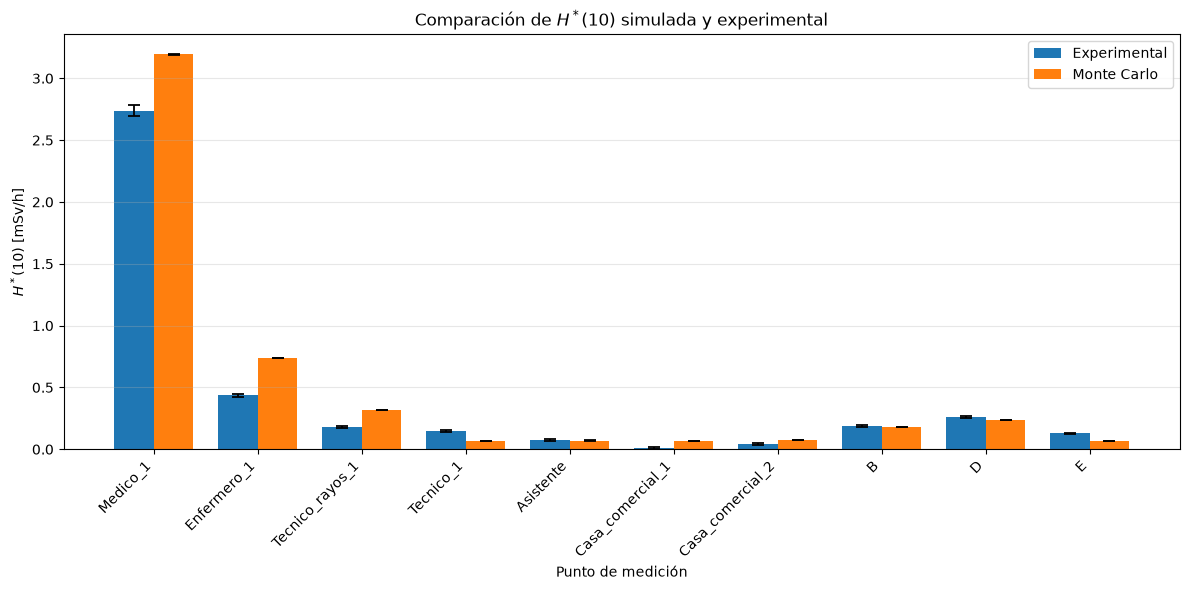

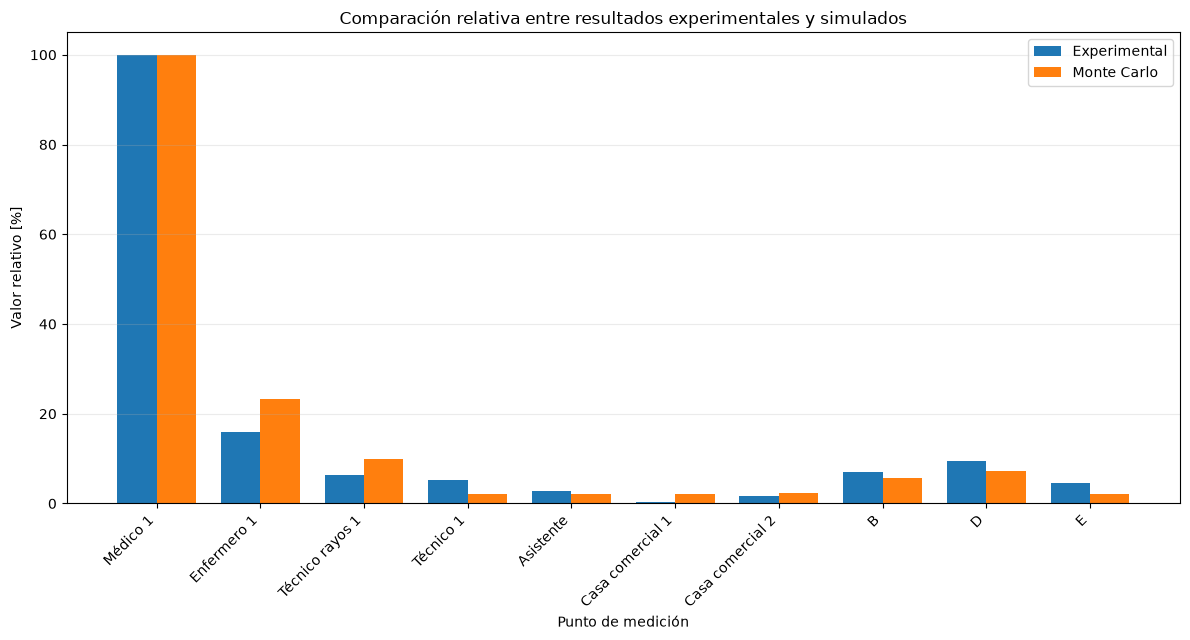

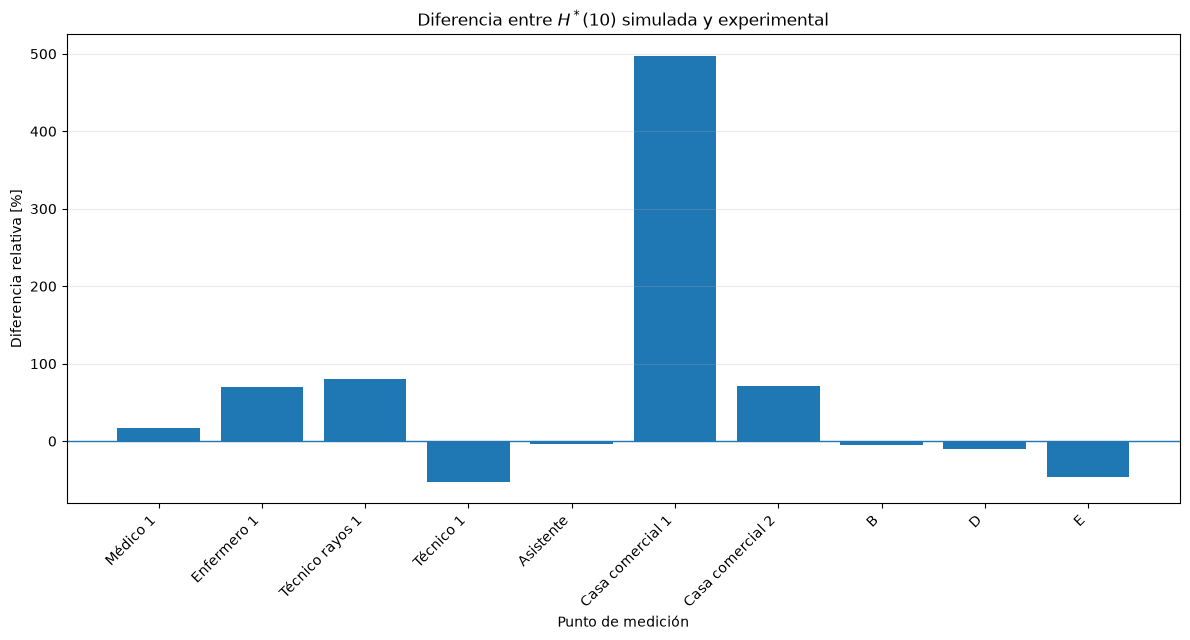

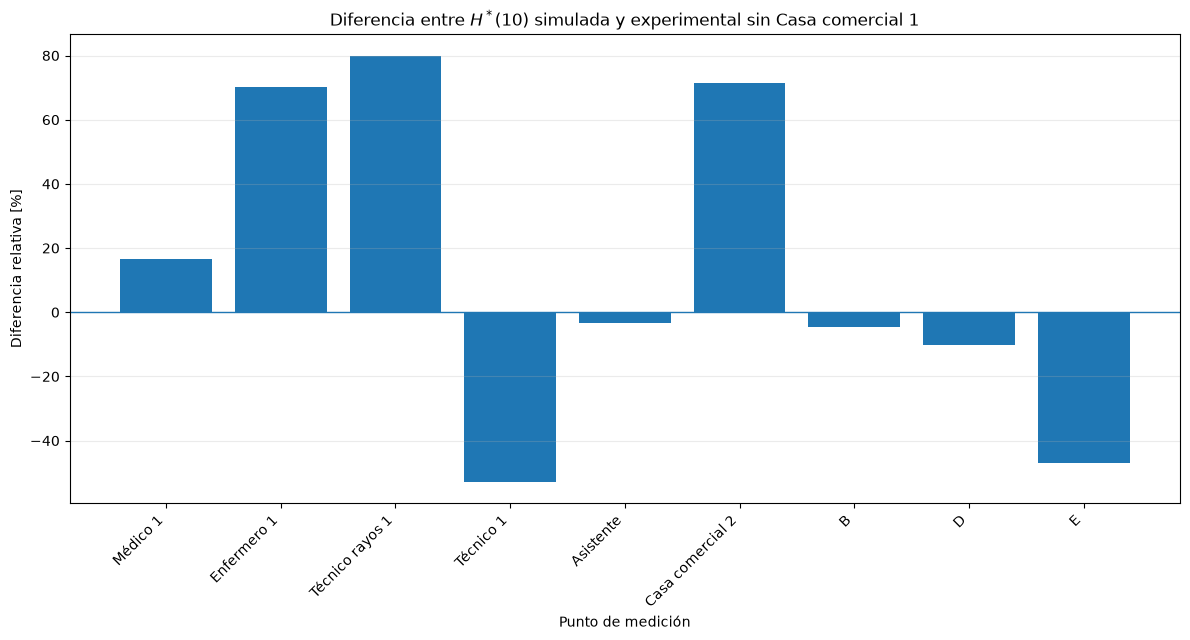

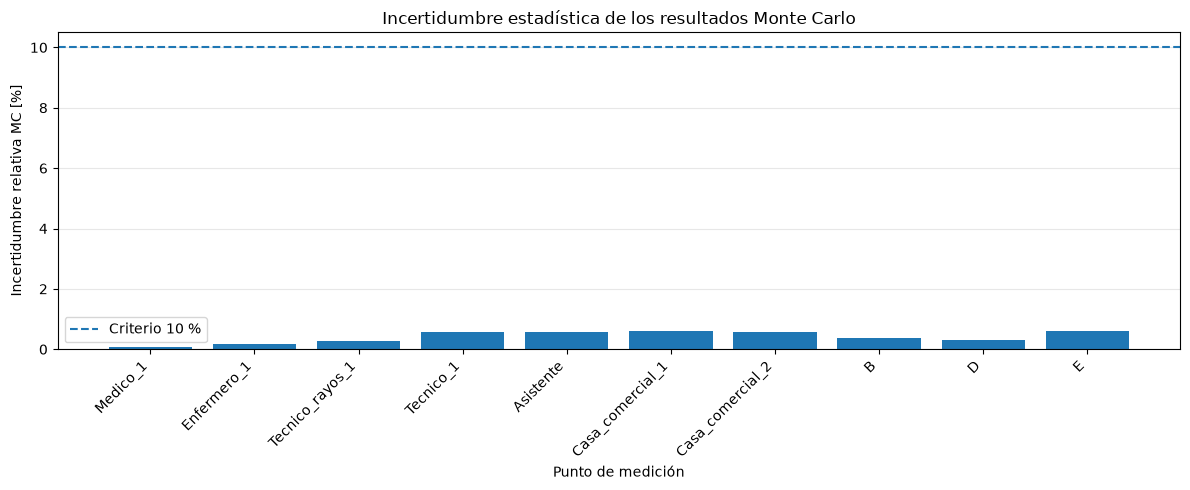

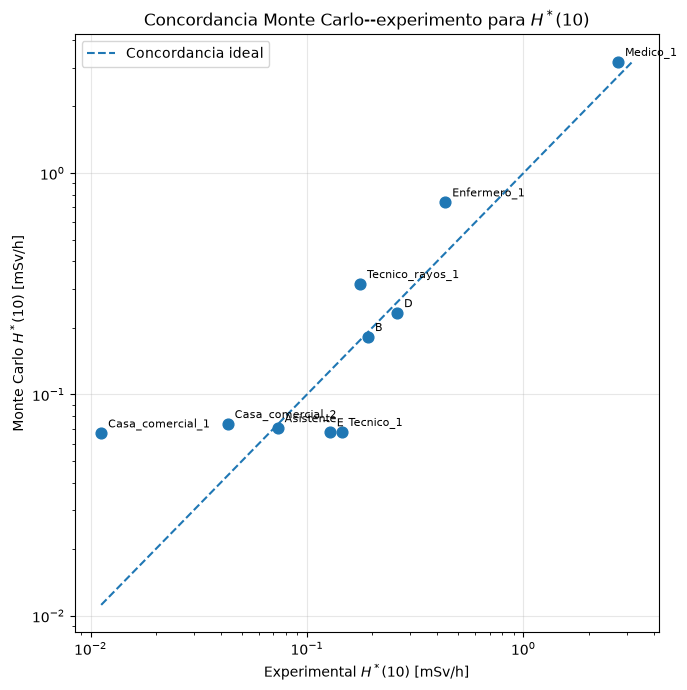


========== RESUMEN PARA EL INFORME ==========
Incertidumbre MC media = 0.41 %
Incertidumbre MC máxima = 0.61 %
Puntos con u_MC <= 10 % = 10/10
Diferencia absoluta media MC-exp = 85.38 %
Diferencia media del patrón relativo = 2.28 puntos porcentuales

Figuras guardadas en:
output_artis_zee/main/figures
Máximo global del mapa = 2.0486289126511822e-07
Máximo para normalización de sala = 1.556614230895994e-08
Referencia P99 = 4.513740434047992e-09
Máximo / P99 = 3.448612638764428


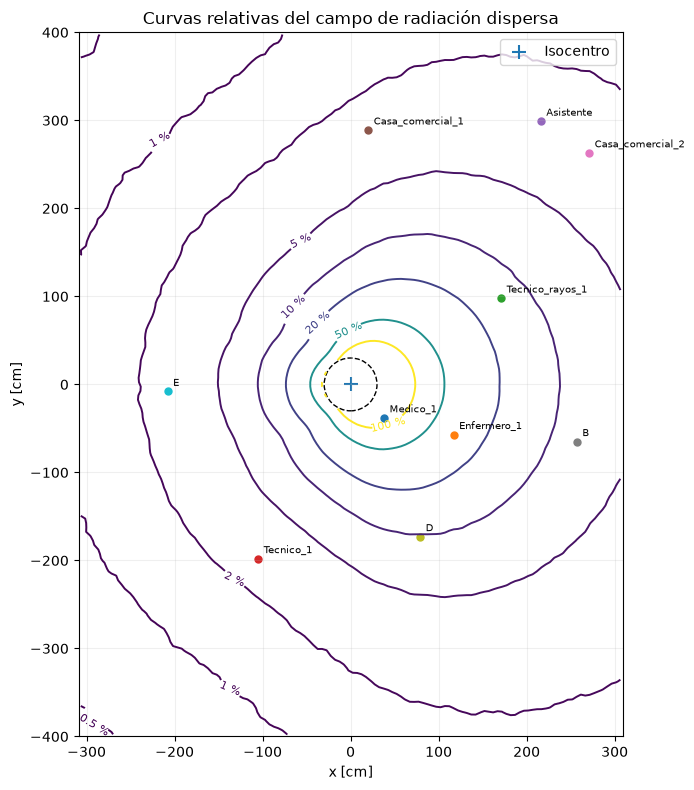

,Punto,MC_Hstar_mSv_h,Experimental_Hstar_mSv_h,Factor_MC_EXP,u_MC_percent
0,Medico_1,3.193262,2.73800,1.166275,0.084261
1,Enfermero_1,0.740729,0.43550,1.700871,0.177726
2,Tecnico_rayos_1,0.316730,0.17600,1.799602,0.273729
3,Tecnico_1,0.067990,0.14450,0.470518,0.577803
4,Asistente,0.070729,0.07320,0.966245,0.583222
5,Casa_comercial_1,0.066934,0.01120,5.976243,0.605049
6,Casa_comercial_2,0.073780,0.04305,1.713828,0.573777
7,B,0.182554,0.19150,0.953286,0.364689
8,D,0.234129,0.26100,0.897046,0.315914
9,E,0.067757,0.12750,0.531430,0.590118


Factor mediano MC/EXP = 1.0662598974841504
Factor mínimo = 0.4705181701613074
Factor máximo = 5.976243478621913
Tasa de dosis mínima válida = 0.007471947656319374 mGy/h
Mediana = 0.053750201822314686 mGy/h
P95 = 0.6134542281481786 mGy/h
P99 = 2.549731584670285 mGy/h
Máximo = 80.37490510479806 mGy/h


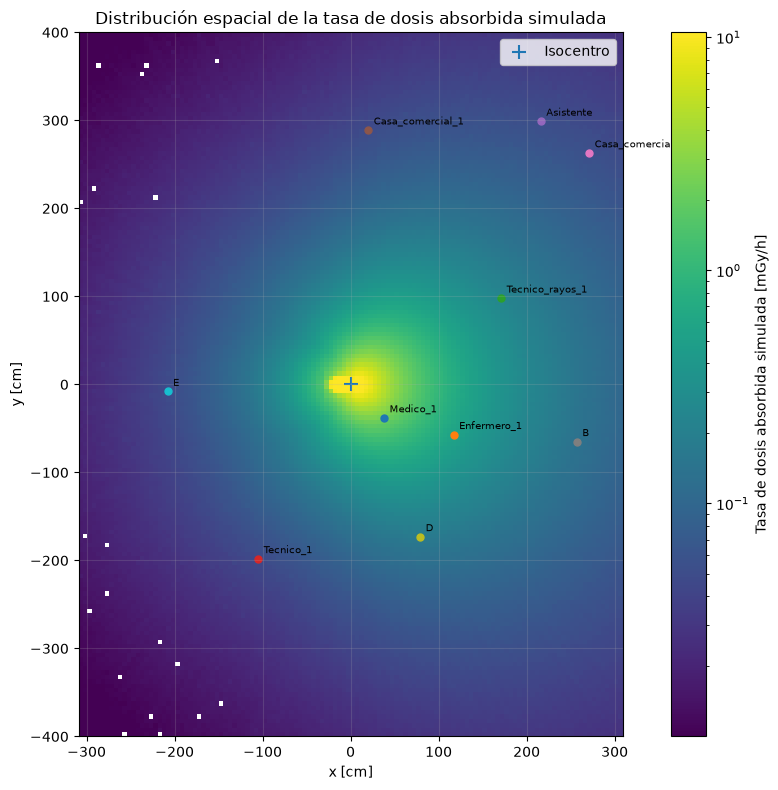

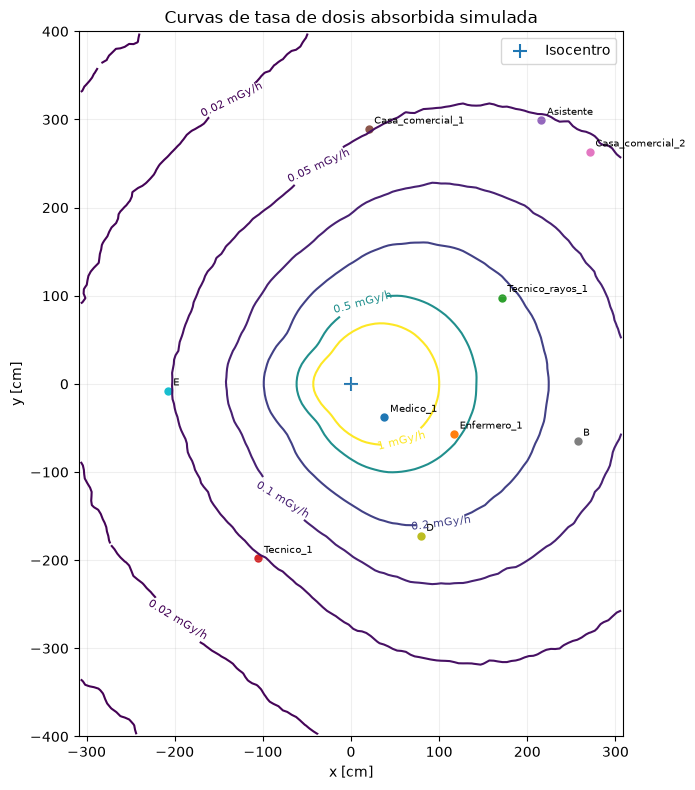


========== CONVERGENCIA DE LA MALLA ==========



,Indicador,Valor
0,Número total de vóxeles,19840
1,Mediana de u_MC,1.50 %
2,Media de u_MC,1.60 %
3,Percentil 90 de u_MC,2.60 %
4,Percentil 95 de u_MC,2.97 %
5,Máxima u_MC,16.15 %
6,Vóxeles con u_MC <= 5 %,99.22 %
7,Vóxeles con u_MC <= 10 %,99.90 %
8,Vóxeles con u_MC <= 20 %,100.00 %



Archivos guardados en:
output_artis_zee/main/figures


In [13]:
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter



# ------------------------------------------------------------
# CARPETA DE SALIDA
# ------------------------------------------------------------

FIGURES_DIR = Path(
    MAIN_OUTPUT_DIR
) / "figures"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# COPIA Y PREPARACIÓN DE DATOS
# ------------------------------------------------------------

df_plot = df_hstar.copy()

points = (
    df_plot["Punto"]
    .astype(str)
    .to_numpy()
)

mc = (
    df_plot["MC_Hstar_mSv_h"]
    .astype(float)
    .to_numpy()
)

exp = (
    df_plot["Experimental_Hstar_mSv_h"]
    .astype(float)
    .to_numpy()
)

u_mc_percent = (
    df_plot["u_MC_percent"]
    .astype(float)
    .to_numpy()
)

u_exp = pd.to_numeric(
    df_plot["u_exp_mSv_h"],
    errors="coerce"
).to_numpy()

# Incertidumbre MC absoluta en mSv/h
u_mc = (
    mc
    * u_mc_percent
    / 100.0
)

difference_percent = (
    df_plot["Diferencia_percent"]
    .astype(float)
    .to_numpy()
)

mc_rel = (
    df_plot["MC_rel_percent"]
    .astype(float)
    .to_numpy()
)

exp_rel = (
    df_plot["EXP_rel_percent"]
    .astype(float)
    .to_numpy()
)

x = np.arange(
    len(points)
)


# ============================================================
# FIGURA 1
# COMPARACIÓN ABSOLUTA H*(10)
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 6)
)

width = 0.38

ax.bar(
    x - width / 2,
    exp,
    width,
    label="Experimental"
)

ax.bar(
    x + width / 2,
    mc,
    width,
    label="Monte Carlo"
)

# Barras de incertidumbre 
valid_exp_unc = np.isfinite(
    u_exp
)

# Incertidumbre experimental
ax.errorbar(
    x - width / 2,
    exp,
    yerr=u_exp,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=1.3,
    elinewidth=1.3,
    zorder=5
)

# Incertidumbre Monte Carlo
ax.errorbar(
    x + width / 2,
    mc,
    yerr=u_mc,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=1.3,
    elinewidth=1.3,
    zorder=5
)
ax.set_xticks(
    x
)

ax.set_xticklabels(
    points,
    rotation=45,
    ha="right"
)

ax.set_ylabel(
    r"$H^*(10)$ [mSv/h]"
)

ax.set_xlabel(
    "Punto de medición"
)

ax.set_title(
    r"Comparación de $H^*(10)$ simulada y experimental"
)

ax.grid(
    axis="y",
    alpha=0.3
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "comparacion_Hstar_absoluta.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURA 2
# DIFERENCIA RELATIVA
# ============================================================

df_rel = df_hstar.copy()

POINT_LABELS = {
    "Medico_1": "Médico 1",
    "Enfermero_1": "Enfermero 1",
    "Tecnico_rayos_1": "Técnico rayos 1",
    "Tecnico_1": "Técnico 1",
    "Asistente": "Asistente",
    "Casa_comercial_1": "Casa comercial 1",
    "Casa_comercial_2": "Casa comercial 2",
    "B": "B",
    "D": "D",
    "E": "E",
}

point_names = (
    df_rel["Punto"]
    .astype(str)
    .to_numpy()
)

point_labels = np.array([
    POINT_LABELS.get(
        name,
        name.replace("_", " ")
    )
    for name in point_names
])

exp_rel = (
    df_rel["EXP_rel_percent"]
    .to_numpy(dtype=float)
)

mc_rel = (
    df_rel["MC_rel_percent"]
    .to_numpy(dtype=float)
)

x = np.arange(
    len(point_names)
)

width = 0.38

fig, ax = plt.subplots(
    figsize=(12, 6.5)
)

ax.bar(
    x - width / 2,
    exp_rel,
    width=width,
    label="Experimental"
)

ax.bar(
    x + width / 2,
    mc_rel,
    width=width,
    label="Monte Carlo"
)

ax.set_xticks(x)

ax.set_xticklabels(
    point_labels,
    rotation=45,
    ha="right"
)

ax.set_xlabel(
    "Punto de medición"
)

ax.set_ylabel(
    "Valor relativo [%]"
)

ax.set_ylim(
    0,
    105
)

ax.set_title(
    "Comparación relativa entre resultados "
    "experimentales y simulados"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "comparacion_relativa_barras.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURA 2
# DIFERENCIA RELATIVA
# ============================================================

df_diff = df_hstar.copy()

df_diff["difference_percent"] = (
    (
        df_diff["MC_Hstar_mSv_h"]
        -
        df_diff["Experimental_Hstar_mSv_h"]
    )
    /
    df_diff["Experimental_Hstar_mSv_h"]
    * 100.0
)

point_names = (
    df_diff["Punto"]
    .astype(str)
    .to_numpy()
)

point_labels = [
    POINT_LABELS.get(
        p,
        p.replace("_", " ")
    )
    for p in point_names
]

difference = (
    df_diff["difference_percent"]
    .to_numpy(dtype=float)
)

x = np.arange(
    len(df_diff)
)

fig, ax = plt.subplots(
    figsize=(12, 6.5)
)

ax.bar(
    x,
    difference
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_xticks(x)

ax.set_xticklabels(
    point_labels,
    rotation=45,
    ha="right"
)

ax.set_xlabel(
    "Punto de medición"
)

ax.set_ylabel(
    "Diferencia relativa [%]"
)

ax.set_title(
    r"Diferencia entre $H^*(10)$ simulada y experimental"
)

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "diferencia_relativa_todos.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURA 3
# DIFERENCIA RELATIVA SIN CASA_COMERCIAL_1
# ============================================================
df_diff_zoom = df_diff[
    df_diff["Punto"] != "Casa_comercial_1"
].copy()

point_names_zoom = (
    df_diff_zoom["Punto"]
    .astype(str)
    .to_numpy()
)

point_labels_zoom = [
    POINT_LABELS.get(
        p,
        p.replace("_", " ")
    )
    for p in point_names_zoom
]

difference_zoom = (
    df_diff_zoom["difference_percent"]
    .to_numpy(dtype=float)
)

x_zoom = np.arange(
    len(df_diff_zoom)
)

fig, ax = plt.subplots(
    figsize=(12, 6.5)
)

ax.bar(
    x_zoom,
    difference_zoom
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_xticks(
    x_zoom
)

ax.set_xticklabels(
    point_labels_zoom,
    rotation=45,
    ha="right"
)

ax.set_xlabel(
    "Punto de medición"
)

ax.set_ylabel(
    "Diferencia relativa [%]"
)

ax.set_title(
    r"Diferencia entre $H^*(10)$ simulada y experimental "
    "sin Casa comercial 1"
)

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "diferencia_relativa_sin_CC1.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURA 4
# INCERTIDUMBRE ESTADÍSTICA MC
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.bar(
    x,
    u_mc_percent
)

# Criterio de convergencia
ax.axhline(
    10.0,
    linestyle="--",
    linewidth=1.5,
    label="Criterio 10 %"
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    points,
    rotation=45,
    ha="right"
)

ax.set_ylabel(
    "Incertidumbre relativa MC [%]"
)

ax.set_xlabel(
    "Punto de medición"
)

ax.set_title(
    "Incertidumbre estadística de los resultados Monte Carlo"
)

ax.grid(
    axis="y",
    alpha=0.3
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "incertidumbre_MC_puntos.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURA 5
# MC VS EXPERIMENTO
# ============================================================

valid = (
    np.isfinite(mc)
    &
    np.isfinite(exp)
    &
    (mc > 0)
    &
    (exp > 0)
)

mc_valid = mc[
    valid
]

exp_valid = exp[
    valid
]

points_valid = points[
    valid
]

fig, ax = plt.subplots(
    figsize=(7, 7)
)

ax.scatter(
    exp_valid,
    mc_valid,
    s=60
)

# Línea ideal y = x
minimum = min(
    np.min(exp_valid),
    np.min(mc_valid)
)

maximum = max(
    np.max(exp_valid),
    np.max(mc_valid)
)

ax.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Concordancia ideal"
)

for i, name in enumerate(
    points_valid
):

    ax.annotate(
        name,
        (
            exp_valid[i],
            mc_valid[i]
        ),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

# Escala log porque los puntos abarcan
# más de un orden de magnitud.
ax.set_xscale(
    "log"
)

ax.set_yscale(
    "log"
)

ax.set_xlabel(
    r"Experimental $H^*(10)$ [mSv/h]"
)

ax.set_ylabel(
    r"Monte Carlo $H^*(10)$ [mSv/h]"
)

ax.set_title(
    r"Concordancia Monte Carlo--experimento para $H^*(10)$"
)

ax.grid(
    alpha=0.3
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "concordancia_MC_experimento.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# RESUMEN 
# ============================================================

mean_mc_unc = np.nanmean(
    u_mc_percent
)

max_mc_unc = np.nanmax(
    u_mc_percent
)

n_below_10 = np.sum(
    u_mc_percent <= 10.0
)

mean_abs_difference = np.nanmean(
    np.abs(
        difference_percent
    )
)

relative_pattern_difference = (
    mc_rel - exp_rel
)

mean_pattern_difference = np.nanmean(
    np.abs(
        relative_pattern_difference
    )
)

print(
    "\n========== RESUMEN PARA EL INFORME =========="
)

print(
    f"Incertidumbre MC media = "
    f"{mean_mc_unc:.2f} %"
)

print(
    f"Incertidumbre MC máxima = "
    f"{max_mc_unc:.2f} %"
)

print(
    f"Puntos con u_MC <= 10 % = "
    f"{n_below_10}/{len(df_plot)}"
)

print(
    f"Diferencia absoluta media MC-exp = "
    f"{mean_abs_difference:.2f} %"
)

print(
    f"Diferencia media del patrón relativo = "
    f"{mean_pattern_difference:.2f} puntos porcentuales"
)

print(
    "\nFiguras guardadas en:"
)

print(
    FIGURES_DIR
)


# ============================================================
# MAPA Y CURVAS DE ISODOSIS RELATIVAS
# ============================================================

room_raw = np.asarray(
    actor_image_to_array(
        room_dose.dose
    )
)

room_raw = np.squeeze(
    room_raw
)

# Algunas imágenes pueden venir transpuestas según
# el orden de ejes de SimpleITK/OpenGATE.
# La comprobación se hace contra nx y ny.

nx = int(
    np.ceil(
        ROOM_SIZE_X_CM
        / ROOM_VOXEL_CM
    )
)

ny = int(
    np.ceil(
        ROOM_SIZE_Y_CM
        / ROOM_VOXEL_CM
    )
)

if room_raw.shape == (
    nx,
    ny
):

    room_raw = (
        room_raw.T
    )

if room_raw.shape != (
    ny,
    nx
):

    raise ValueError(
        "Dimensiones inesperadas del mapa: "
        f"{room_raw.shape}. "
        f"Se esperaba {(ny, nx)}."
    )


# ------------------------------------------------------------
# INCERTIDUMBRE DEL MAPA
# ------------------------------------------------------------

room_unc = np.asarray(
    actor_image_to_array(
        room_dose.dose_uncertainty
    )
)

room_unc = np.squeeze(
    room_unc
)

if room_unc.shape == (
    nx,
    ny
):

    room_unc = (
        room_unc.T
    )


# ------------------------------------------------------------
# MAPA RELATIVO
# ------------------------------------------------------------

room_max = np.nanmax(
    room_raw
)

room_relative = (
    100.0
    * room_raw
    / room_max
)


# ------------------------------------------------------------
# COORDENADAS
# ------------------------------------------------------------

x_edges = np.linspace(
    -ROOM_SIZE_X_CM / 2,
    ROOM_SIZE_X_CM / 2,
    nx + 1
)

y_edges = np.linspace(
    -ROOM_SIZE_Y_CM / 2,
    ROOM_SIZE_Y_CM / 2,
    ny + 1
)

x_centers = (
    0.5
    * (
        x_edges[:-1]
        + x_edges[1:]
    )
)

y_centers = (
    0.5
    * (
        y_edges[:-1]
        + y_edges[1:]
    )
)

X, Y = np.meshgrid(
    x_centers,
    y_centers
)


# ------------------------------------------------------------
# MÁSCARA DE REGIONES POCO CONFIABLES
# ------------------------------------------------------------

valid_mask = (
    np.isfinite(room_relative)
    &
    np.isfinite(room_unc)
    &
    (room_relative >= 5.0)
    &
    (room_unc * 100.0 <= 10.0)
)

room_for_contours = np.where(
    valid_mask,
    room_relative,
    np.nan
)




# ============================================================
# MAPA Y CURVAS DE ISODOSIS RELATIVAS
# ============================================================

# ------------------------------------------------------------
# LEER MAPA DE DOSIS E INCERTIDUMBRE
# ------------------------------------------------------------

room_raw = np.asarray(
    actor_image_to_array(
        room_dose.dose
    )
)

room_raw = np.squeeze(
    room_raw
)

room_unc = np.asarray(
    actor_image_to_array(
        room_dose.dose_uncertainty
    )
)

room_unc = np.squeeze(
    room_unc
)

# ------------------------------------------------------------
# AJUSTE DE ORIENTACIÓN
# ------------------------------------------------------------

nx = int(
    np.ceil(
        ROOM_SIZE_X_CM / ROOM_VOXEL_CM
    )
)

ny = int(
    np.ceil(
        ROOM_SIZE_Y_CM / ROOM_VOXEL_CM
    )
)

if room_raw.shape == (nx, ny):
    room_raw = room_raw.T

if room_unc.shape == (nx, ny):
    room_unc = room_unc.T

if room_raw.shape != (ny, nx):
    raise ValueError(
        f"Forma inesperada del mapa: {room_raw.shape}, "
        f"se esperaba {(ny, nx)}"
    )

# ------------------------------------------------------------
# COORDENADAS
# ------------------------------------------------------------

x_edges = np.linspace(
    -ROOM_SIZE_X_CM / 2,
    ROOM_SIZE_X_CM / 2,
    nx + 1
)

y_edges = np.linspace(
    -ROOM_SIZE_Y_CM / 2,
    ROOM_SIZE_Y_CM / 2,
    ny + 1
)

x_centers = 0.5 * (
    x_edges[:-1] + x_edges[1:]
)

y_centers = 0.5 * (
    y_edges[:-1] + y_edges[1:]
)

X, Y = np.meshgrid(
    x_centers,
    y_centers
)

# ------------------------------------------------------------
# ZONA DE EXCLUSIÓN CENTRAL PARA NORMALIZACIÓN
# ------------------------------------------------------------
# Se excluye la región del fantoma / haz primario
# para que el máximo de referencia represente mejor
# la dispersión en la sala.

EXCLUSION_RADIUS_CM = 30.0

R = np.sqrt(
    X**2 + Y**2
)

normalization_mask = (
    R >= EXCLUSION_RADIUS_CM
)

valid_for_norm = (
    np.isfinite(room_raw)
    & normalization_mask
)

if not np.any(valid_for_norm):
    raise ValueError(
        "No hay vóxeles válidos para normalización."
    )

room_max_for_room = np.nanmax(
    room_raw[valid_for_norm]
)

print(
    "Máximo global del mapa =",
    np.nanmax(room_raw)
)

print(
    "Máximo para normalización de sala =",
    room_max_for_room
)

# ------------------------------------------------------------
# MAPA RELATIVO
# ------------------------------------------------------------

room_relative = (
    100.0 * room_raw / room_max_for_room
)

# ------------------------------------------------------------
# MÁSCARA DE VALIDEZ PARA CURVAS
# ------------------------------------------------------------

valid_mask = (
    np.isfinite(room_relative)
    &
    np.isfinite(room_unc)
    &
    (room_relative >= 0.5)
    &
    (room_unc * 100.0 <= 15.0)
)

# ------------------------------------------------------------
# SUAVIZADO SOLO PARA VISUALIZACIÓN DE CURVAS
# ------------------------------------------------------------

room_relative_smooth = gaussian_filter(
    room_relative,
    sigma=1.0
)

room_for_contours = np.where(
    valid_mask,
    room_relative_smooth,
    np.nan
)


# ============================================================
# CURVAS DE ISODOSIS OCUPACIONALES
# NORMALIZACIÓN ROBUSTA
# ============================================================
from scipy.ndimage import gaussian_filter

# ------------------------------------------------------------
# CENTROS DE VÓXEL
# ------------------------------------------------------------

x_centers = 0.5 * (
    x_edges[:-1]
    + x_edges[1:]
)

y_centers = 0.5 * (
    y_edges[:-1]
    + y_edges[1:]
)

X, Y = np.meshgrid(
    x_centers,
    y_centers
)

# ------------------------------------------------------------
# EXCLUIR REGIÓN CENTRAL
# ------------------------------------------------------------

EXCLUSION_RADIUS_CM = 30.0

R = np.sqrt(
    X**2 + Y**2
)

outside_center = (
    R >= EXCLUSION_RADIUS_CM
)

# ------------------------------------------------------------
# VÓXELES VÁLIDOS PARA DEFINIR REFERENCIA
# ------------------------------------------------------------

reference_mask = (
    outside_center
    &
    np.isfinite(room_raw)
    &
    (room_raw > 0)
)

values_reference = (
    room_raw[
        reference_mask
    ]
)

if len(values_reference) == 0:

    raise RuntimeError(
        "No existen vóxeles válidos."
    )

# ------------------------------------------------------------
# REFERENCIA ROBUSTA:
# PERCENTIL 99 EN VEZ DEL MÁXIMO
# ------------------------------------------------------------

REFERENCE_PERCENTILE = 99.0

dose_reference = np.percentile(
    values_reference,
    REFERENCE_PERCENTILE
)

print(
    "Referencia P99 =",
    dose_reference
)

print(
    "Máximo / P99 =",
    np.nanmax(
        values_reference
    )
    / dose_reference
)

# ------------------------------------------------------------
# DISTRIBUCIÓN RELATIVA
# ------------------------------------------------------------

room_relative = (
    100.0
    * room_raw
    / dose_reference
)

# ------------------------------------------------------------
# INCERTIDUMBRE
#
# Para visualización de las curvas usaría 20 %,
# manteniendo 10 % como criterio cuantitativo principal.
# ------------------------------------------------------------

MAX_U_CONTOURS_PERCENT = 20.0

valid_contours = (
    outside_center
    &
    np.isfinite(room_relative)
    &
    np.isfinite(room_unc)
    &
    (
        room_unc * 100.0
        <= MAX_U_CONTOURS_PERCENT
    )
    &
    (
        room_relative >= 0.1
    )
)

# ------------------------------------------------------------
# SUAVIZADO ÚNICAMENTE GRÁFICO
# ------------------------------------------------------------

room_smooth = gaussian_filter(
    room_relative,
    sigma=0.8
)

room_plot = np.where(
    valid_contours,
    room_smooth,
    np.nan
)

# ------------------------------------------------------------
# NIVELES LOGARÍTMICOS / SEMILOGARÍTMICOS
# ------------------------------------------------------------

levels = [
    0.1,
    0.2,
    0.5,
    1,
    2,
    5,
    10,
    20,
    50,
    100
]

# ============================================================
# FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 8)
)

cs = ax.contour(
    X,
    Y,
    room_plot,
    levels=levels,
    linewidths=1.4
)

ax.clabel(
    cs,
    inline=True,
    fontsize=8,
    fmt=lambda value:
        f"{value:g} %"
)

# ------------------------------------------------------------
# PUNTOS EXPERIMENTALES
# ------------------------------------------------------------

for point_name, point_info in (
    MEASUREMENT_POINTS.items()
):

    xyz = get_point_xyz(
        point_info
    )

    ax.scatter(
        xyz[0],
        xyz[1],
        s=25
    )

    ax.annotate(
        point_name,
        (
            xyz[0],
            xyz[1]
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7
    )

# ------------------------------------------------------------
# ISOCENTRO
# ------------------------------------------------------------

ax.scatter(
    0,
    0,
    marker="+",
    s=100,
    label="Isocentro"
)

circle = plt.Circle(
    (0, 0),
    EXCLUSION_RADIUS_CM,
    fill=False,
    linestyle="--",
    linewidth=1
)

ax.add_patch(
    circle
)

ax.set_xlim(
    -ROOM_SIZE_X_CM / 2,
    ROOM_SIZE_X_CM / 2
)

ax.set_ylim(
    -ROOM_SIZE_Y_CM / 2,
    ROOM_SIZE_Y_CM / 2
)

ax.set_xlabel(
    "x [cm]"
)

ax.set_ylabel(
    "y [cm]"
)

ax.set_title(
    "Curvas relativas del campo de radiación dispersa"
)

ax.set_aspect(
    "equal"
)

ax.grid(
    alpha=0.2
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "curvas_isodosis_ocupacionales_P99.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

df_hstar["Factor_MC_EXP"] = (
    df_hstar["MC_Hstar_mSv_h"]
    /
    df_hstar["Experimental_Hstar_mSv_h"]
)

display(
    df_hstar[
        [
            "Punto",
            "MC_Hstar_mSv_h",
            "Experimental_Hstar_mSv_h",
            "Factor_MC_EXP",
            "u_MC_percent"
        ]
    ]
)

print(
    "Factor mediano MC/EXP =",
    df_hstar["Factor_MC_EXP"].median()
)

print(
    "Factor mínimo =",
    df_hstar["Factor_MC_EXP"].min()
)

print(
    "Factor máximo =",
    df_hstar["Factor_MC_EXP"].max()
)




# ============================================================
# MAPA ABSOLUTO DE TASA DE DOSIS ABSORBIDA
# MONTE CARLO
# ============================================================




# ============================================================
# 1. CENTROS DE LOS VÓXELES
# ============================================================

x_centers = 0.5 * (
    x_edges[:-1]
    + x_edges[1:]
)

y_centers = 0.5 * (
    y_edges[:-1]
    + y_edges[1:]
)

X, Y = np.meshgrid(
    x_centers,
    y_centers
)


# ============================================================
# 2. CONVERSIÓN A DOSIS ABSOLUTA
# ============================================================

# room_raw:
# dosis obtenida en la corrida Monte Carlo [Gy]
#
# N_PRIMARIES:
# número de historias de la simulación principal
#
# equivalent_real_primaries:
# número equivalente de primarios correspondiente
# a la condición experimental

room_dose_Gy = (
    room_raw
    / N_PRIMARIES
    * equivalent_real_primaries
)


# ============================================================
# 3. CONVERTIR A TASA DE DOSIS
#
# Gy -> mGy
# exposición -> hora
# ============================================================

room_dose_rate_mGy_h = (
    room_dose_Gy
    * 1000.0
    * 3600.0
    / EXPOSURE_TIME_S
)


# ============================================================
# 4. MÁSCARA POR INCERTIDUMBRE
# ============================================================

MAX_U_PERCENT = 10.0

valid = (
    np.isfinite(room_dose_rate_mGy_h)
    &
    (room_dose_rate_mGy_h > 0)
    &
    np.isfinite(room_unc)
    &
    (
        room_unc * 100.0
        <= MAX_U_PERCENT
    )
)

dose_plot = np.where(
    valid,
    room_dose_rate_mGy_h,
    np.nan
)


# ============================================================
# 5. DIAGNÓSTICO
# ============================================================

valid_values = (
    room_dose_rate_mGy_h[
        valid
    ]
)

print(
    "Tasa de dosis mínima válida =",
    np.nanmin(valid_values),
    "mGy/h"
)

print(
    "Mediana =",
    np.nanmedian(valid_values),
    "mGy/h"
)

print(
    "P95 =",
    np.nanpercentile(
        valid_values,
        95
    ),
    "mGy/h"
)

print(
    "P99 =",
    np.nanpercentile(
        valid_values,
        99
    ),
    "mGy/h"
)

print(
    "Máximo =",
    np.nanmax(valid_values),
    "mGy/h"
)


# ============================================================
# 6. MAPA ABSOLUTO
#
# Se utiliza escala logarítmica únicamente para visualización.
# Los valores siguen siendo absolutos en mGy/h.
# ============================================================

vmin = np.nanpercentile(
    valid_values,
    1
)

vmax = np.nanpercentile(
    valid_values,
    99.9
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

mesh = ax.pcolormesh(
    x_edges,
    y_edges,
    dose_plot,
    shading="auto",
    norm=LogNorm(
        vmin=vmin,
        vmax=vmax
    )
)

cbar = fig.colorbar(
    mesh,
    ax=ax
)

cbar.set_label(
    r"Tasa de dosis absorbida simulada [mGy/h]"
)


# ============================================================
# 7. PUNTOS EXPERIMENTALES
# ============================================================

for point_name, point_info in (
    MEASUREMENT_POINTS.items()
):

    xyz = get_point_xyz(
        point_info
    )

    ax.scatter(
        xyz[0],
        xyz[1],
        s=25
    )

    ax.annotate(
        point_name,
        (
            xyz[0],
            xyz[1]
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7
    )


# ============================================================
# 8. ISOCENTRO
# ============================================================

ax.scatter(
    0,
    0,
    marker="+",
    s=100,
    label="Isocentro"
)


# ============================================================
# 9. FORMATO
# ============================================================

ax.set_xlim(
    -ROOM_SIZE_X_CM / 2,
    ROOM_SIZE_X_CM / 2
)

ax.set_ylim(
    -ROOM_SIZE_Y_CM / 2,
    ROOM_SIZE_Y_CM / 2
)

ax.set_xlabel(
    "x [cm]"
)

ax.set_ylabel(
    "y [cm]"
)

ax.set_title(
    "Distribución espacial de la tasa de dosis absorbida simulada"
)

ax.set_aspect(
    "equal"
)

ax.grid(
    alpha=0.2
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "mapa_tasa_dosis_absoluta_mGy_h.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# CURVAS DE ISODOSIS ABSOLUTAS
# ============================================================

dose_smooth = gaussian_filter(
    room_dose_rate_mGy_h,
    sigma=0.8
)

dose_contours = np.where(
    valid,
    dose_smooth,
    np.nan
)


# ------------------------------------------------------------
# NIVELES ABSOLUTOS
#
# Ajustar después de observar mínimo, P95, P99 y máximo.
# ------------------------------------------------------------

levels_abs = [
    0.01,
    0.02,
    0.05,
    0.10,
    0.20,
    0.50,
    1.00,
]


fig, ax = plt.subplots(
    figsize=(10, 8)
)

cs = ax.contour(
    X,
    Y,
    dose_contours,
    levels=levels_abs,
    linewidths=1.5
)

ax.clabel(
    cs,
    inline=True,
    fontsize=8,
    fmt=lambda value:
        f"{value:g} mGy/h"
)


# ============================================================
# PUNTOS EXPERIMENTALES
# ============================================================

for point_name, point_info in (
    MEASUREMENT_POINTS.items()
):

    xyz = get_point_xyz(
        point_info
    )

    ax.scatter(
        xyz[0],
        xyz[1],
        s=25
    )

    ax.annotate(
        point_name,
        (
            xyz[0],
            xyz[1]
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7
    )


# ============================================================
# ISOCENTRO
# ============================================================

ax.scatter(
    0,
    0,
    marker="+",
    s=100,
    label="Isocentro"
)


# ============================================================
# FORMATO
# ============================================================

ax.set_xlim(
    -ROOM_SIZE_X_CM / 2,
    ROOM_SIZE_X_CM / 2
)

ax.set_ylim(
    -ROOM_SIZE_Y_CM / 2,
    ROOM_SIZE_Y_CM / 2
)

ax.set_xlabel(
    "x [cm]"
)

ax.set_ylabel(
    "y [cm]"
)

ax.set_title(
    "Curvas de tasa de dosis absorbida simulada"
)

ax.set_aspect(
    "equal"
)

ax.grid(
    alpha=0.2
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "curvas_dosis_absolutas_mGy_h.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 3. CONVERGENCIA DE LA MALLA
# ============================================================

# La salida de OpenGATE se almacena como incertidumbre relativa,
# por lo que se convierte a porcentaje.

room_unc_percent = (
    np.asarray(room_unc, dtype=float)
    * 100.0
)

# Solo valores finitos
valid_unc = room_unc_percent[
    np.isfinite(room_unc_percent)
]

if len(valid_unc) == 0:

    raise RuntimeError(
        "No existen valores válidos de incertidumbre "
        "en la malla."
    )


# ------------------------------------------------------------
# ESTADÍSTICAS
# ------------------------------------------------------------

n_total = valid_unc.size

median_u = np.median(
    valid_unc
)

mean_u = np.mean(
    valid_unc
)

p90_u = np.percentile(
    valid_unc,
    90
)

p95_u = np.percentile(
    valid_unc,
    95
)

max_u = np.max(
    valid_unc
)

n_under_5 = np.sum(
    valid_unc <= 5.0
)

n_under_10 = np.sum(
    valid_unc <= 10.0
)

n_under_20 = np.sum(
    valid_unc <= 20.0
)

pct_under_5 = (
    100.0
    * n_under_5
    / n_total
)

pct_under_10 = (
    100.0
    * n_under_10
    / n_total
)

pct_under_20 = (
    100.0
    * n_under_20
    / n_total
)


# ============================================================
# TABLA DE CONVERGENCIA
# ============================================================

df_convergence = pd.DataFrame(
    {
        "Indicador": [
            "Número total de vóxeles",
            "Mediana de u_MC",
            "Media de u_MC",
            "Percentil 90 de u_MC",
            "Percentil 95 de u_MC",
            "Máxima u_MC",
            "Vóxeles con u_MC <= 5 %",
            "Vóxeles con u_MC <= 10 %",
            "Vóxeles con u_MC <= 20 %",
        ],

        "Valor": [
            f"{n_total:d}",
            f"{median_u:.2f} %",
            f"{mean_u:.2f} %",
            f"{p90_u:.2f} %",
            f"{p95_u:.2f} %",
            f"{max_u:.2f} %",
            f"{pct_under_5:.2f} %",
            f"{pct_under_10:.2f} %",
            f"{pct_under_20:.2f} %",
        ],
    }
)

print(
    "\n========== CONVERGENCIA DE LA MALLA ==========\n"
)

display(
    df_convergence
)



# ============================================================
# EXPORTAR TABLA
# ============================================================

df_convergence.to_csv(
    FIGURES_DIR
    / "resumen_convergencia_malla.csv",
    index=False
)

print(
    "\nArchivos guardados en:"
)

print(
    FIGURES_DIR
)

## 14. Control de calidad y resumen reproducible

Esta sección imprime únicamente los parámetros que realmente intervienen en la configuración final y los diagnósticos esenciales de la normalización. Los datos del certificado se conservan como referencia independiente.


In [14]:

# ============================================================
# DATOS DEL CERTIFICADO
# ============================================================

QA_HVL_KVP = 81
QA_HVL_AL_MM = 3.04

QA_OUTPUT_NO_CU = np.array([
    71.2116872,
    73.00281955,
    73.59208524,
    74.1078208,
    76.00243013
])

QA_OUTPUT_CU03 = np.array([
    16.43475751,
    16.63865546,
    16.95346629,
    17.14416336,
    17.46513038
])

print("========== RESUMEN DEL MODELO ==========")
print("Sistema:", SYSTEM_NAME)
print("Tubo:", TUBE_MODEL)
print("kVp:", TUBE_VOLTAGE_KV)
print("mAs:", MAS)
print("Cu [mm]:", CU_FILTER_MM)
print("Al equivalente SpekPy [mm]:", AL_EQUIV_MM)
print("HVL espectro final [mm Al]:", HVL_AL_MM)
print("Ángulo ánodo [°]:", ANODE_ANGLE_DEG)
print("LAO [°]:", LAO_DEG)
print("SID [cm]:", SID_CM)
print("Foco-isocentro [cm]:", SOURCE_TO_ISOCENTER_CM)
print("Campo nominal [cm]:", FOV_NOMINAL_CM)
print("Campo medido [cm]:", FIELD_MEASURED_CM)
print("Semiángulo [°]:", theta_max / deg)
print("Altura dosímetro sobre suelo [cm]:",
      DOSIMETER_HEIGHT_FLOOR_CM)
print("z dosímetro respecto al isocentro [cm]:",
      DOSIMETER_Z_CM)
print("Ka,r usado [mGy]:", KA_R_REFERENCE_MGY)
print("Normalización:", KA_R_REFERENCE_SOURCE)

print("\n========== CONTROL DE CALIDAD ==========")
print("HVL medida a 81 kVp [mm Al]:", QA_HVL_AL_MM)
print(
    "Rendimiento medio sin Cu [uGy/mAs]:",
    np.mean(QA_OUTPUT_NO_CU)
)
print(
    "Rendimiento medio con 0.3 mm Cu [uGy/mAs]:",
    np.mean(QA_OUTPUT_CU03)
)



print("N_PRIMARIES =", N_PRIMARIES)
print(
    "N_PRIMARIES_NORMALIZATION =",
    N_PRIMARIES_NORMALIZATION
)

print(
    "Ka,r referencia [mGy] =",
    KA_R_REFERENCE_MGY
)

print(
    "Dosis IRP raw [Gy] =",
    irp_dose_raw
)

print(
    "Dosis IRP/primario [Gy] =",
    irp_dose_per_primary_Gy
)

print(
    "Primarios equivalentes =",
    equivalent_real_primaries
)

doctor_actor = point_actors["Medico_1"]

doctor_raw = float(
    np.squeeze(
        actor_image_to_array(
            doctor_actor.dose
        )
    )
)

print("Dosis MC IRP raw [Gy] =", irp_dose_raw)
print("Dosis MC médico raw [Gy] =", doctor_raw)


doctor_per_primary = (
    doctor_raw / N_PRIMARIES
)

irp_per_primary = (
    irp_dose_raw
    / N_PRIMARIES_NORMALIZATION
)

doctor_irp_ratio = (
    doctor_per_primary
    / irp_per_primary
)

print(
    "Dosis médico/primario [Gy] =",
    doctor_per_primary
)

print(
    "Dosis IRP/primario [Gy] =",
    irp_per_primary
)

print(
    "Médico / IRP por primario =",
    doctor_irp_ratio
)


print(
    "Incertidumbre IRP [%] =",
    irp_uncertainty * 100.0
)


# ============================================================
# DIAGNÓSTICO DEL IRP
# ============================================================

tle_dose_raw = float(
    np.squeeze(
        actor_image_to_array(
            irp_dose.dose
        )
    )
)

tle_unc_raw = float(
    np.squeeze(
        actor_image_to_array(
            irp_dose.dose_uncertainty
        )
    )
)



# ============================================================
# DIAGNÓSTICO DE LA MALLA DE SALA
# ============================================================

print(
    "========== DIAGNÓSTICO DE LA MALLA =========="
)

positive = (
    np.isfinite(room_raw)
    & (room_raw > 0)
)

print(
    "Vóxeles totales =",
    room_raw.size
)

print(
    "Vóxeles > 0 =",
    np.sum(positive)
)

print(
    "Fracción > 0 [%] =",
    100 * np.mean(positive)
)

if np.any(positive):

    vals = room_raw[positive]

    print("\nPercentiles de la magnitud:")

    for p in [
        1,
        5,
        10,
        25,
        50,
        75,
        90,
        95,
        99,
        99.5,
        99.9,
        100
    ]:

        print(
            f"P{p} =",
            np.percentile(vals, p)
        )

# ------------------------------------------------------------
# INCERTIDUMBRE
# ------------------------------------------------------------

valid_u = (
    np.isfinite(room_unc)
    & (room_unc > 0)
)

if np.any(valid_u):

    u_percent = (
        100.0
        * room_unc[valid_u]
    )

    print(
        "\nMediana u [%] =",
        np.median(u_percent)
    )

    print(
        "P90 u [%] =",
        np.percentile(
            u_percent,
            90
        )
    )

    print(
        "Vóxeles con u <= 10 % [%] =",
        100.0
        * np.mean(
            u_percent <= 10.0
        )
    )

    print(
        "Vóxeles con u <= 20 % [%] =",
        100.0
        * np.mean(
            u_percent <= 20.0
        )
    )

print(
    "========== VALIDACIÓN IRP =========="
)

print(
    "TLE Dose [Gy] =",
    irp_dose_raw
)

print(
    "TLE incertidumbre [%] =",
    irp_uncertainty * 100.0
)



========== RESUMEN DEL MODELO ==========
Sistema: Siemens Artis Zee Ceiling
Tubo: MEGALIX Cat Plus 125/20/40/80-122GW
kVp: 73.3
mAs: 18.947249999999997
Cu [mm]: 0.1
Al equivalente SpekPy [mm]: 0.2
HVL espectro final [mm Al]: 2.79
Ángulo ánodo [°]: 12.0
LAO [°]: -35.0
SID [cm]: 104.0
Foco-isocentro [cm]: 78.5
Campo nominal [cm]: 22.0
Campo medido [cm]: 20.74
Semiángulo [°]: 5.9204107652608124
Altura dosímetro sobre suelo [cm]: 124.0
z dosímetro respecto al isocentro [cm]: 16.0
Ka,r usado [mGy]: 2.6920483987227963
Normalización: SpekPy (estimación del modelo)

========== CONTROL DE CALIDAD ==========
HVL medida a 81 kVp [mm Al]: 3.04
Rendimiento medio sin Cu [uGy/mAs]: 73.583368584
Rendimiento medio con 0.3 mm Cu [uGy/mAs]: 16.927234600000002
N_PRIMARIES = 1200000000
N_PRIMARIES_NORMALIZATION = 120000000
Ka,r referencia [mGy] = 2.6920483987227963
Dosis IRP raw [Gy] = 8.23392551695932e-07
Dosis IRP/primario [Gy] = 6.8616045974661e-15
Primarios equivalentes = 392335110612.01843
Dosis MC IR

## Histograma de convergencia de simulaición

Vóxeles válidos: 19840
Mediana: 1.50 %
Media: 1.60 %
Máximo: 16.15 %
Vóxeles <= 10 %: 99.90 %


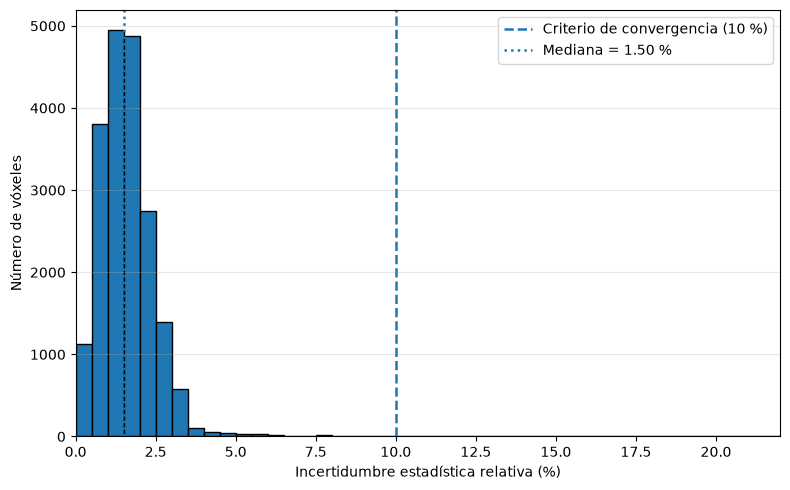

In [3]:


archivo = Path("output_artis_zee/main/room_dose_xy_uncertainty.mhd")

img = sitk.ReadImage(str(archivo))

room_unc = sitk.GetArrayFromImage(img)

room_unc_percent = np.asarray(room_unc, dtype=float) * 100.0

valid_unc = room_unc_percent[
    np.isfinite(room_unc_percent)
]

median_u = np.median(valid_unc)
mean_u = np.mean(valid_unc)

print("Vóxeles válidos:", valid_unc.size)
print(f"Mediana: {median_u:.2f} %")
print(f"Media: {mean_u:.2f} %")
print(f"Máximo: {np.max(valid_unc):.2f} %")
print(f"Vóxeles <= 10 %: {np.mean(valid_unc <= 10)*100:.2f} %")


fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    valid_unc,
    bins=np.arange(0, max(22.5, np.ceil(valid_unc.max()) + 0.5), 0.5),
    edgecolor="black"
)

ax.axvline(
    10,
    linestyle="--",
    linewidth=1.8,
    label="Criterio de convergencia (10 %)"
)

ax.axvline(
    median_u,
    linestyle=":",
    linewidth=1.8,
    label=f"Mediana = {median_u:.2f} %"
)

ax.set_xlabel("Incertidumbre estadística relativa (%)")
ax.set_ylabel("Número de vóxeles")
ax.set_xlim(0, 22)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Guardar en la carpeta actual
plt.savefig(
    "histograma_convergencia_malla.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "histograma_convergencia_malla.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
